# Closure tests — part 2: shape + prior closure

Shared plotting code lives in `closure_tests_common.py`; this notebook only loads inputs and makes the plots.

Differential pT panels at 100 GeV and above are taken from the RL-rebinned files (`unfolded_tests_AA_AB_BB_rad_rebinRL2.root`, `unfolded_rebinRL2.root`).

In [1]:
import os
import numpy as np
import pandas as pd
import uproot as ur

import sys
utils_path = '/global/cfs/cdirs/alice/blianggi/mypyjetty/pyjetty/pyjetty/alice_analysis/analysis/user/jse/3Dunfolding/'
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)
from jupyter_utils import *

import matplotlib.pyplot as plt
from IPython.display import Image
pd.set_option('display.max_columns', None) # to see all columns of df.head()
pd.set_option('display.max_rows', None)

from matplotlib.patches import PathPatch
from matplotlib.path import Path
from matplotlib.ticker import MaxNLocator, NullFormatter

# Lauren's colors
L_colors = ['red', 'darkorange', 'limegreen', 'green', 'deepskyblue', 'blue', 'black']
L_linestyles = ['solid', 'dashed']
L_markers = ['s', '^', 'v', 'd', 'P']

In [2]:
import sys
sys.path.insert(0, '/global/cfs/cdirs/alice/blianggi/mypyjetty/pyjetty/pyjetty/alice_analysis/analysis/user/jse/3Dunfolding/')

import closure_tests_common as ctc
from closure_tests_common import *   # plotting functions + binning constants (incl. rebinned R_L binning)

inp = ctc.load_inputs()

# aliases so the section cells below work unchanged
labels, n_iter = inp.labels, inp.n_iter
binning, bincenters, binwidths = inp.binning, inp.bincenters, inp.binwidths
L_colors, L_markers = inp.L_colors, inp.L_markers

f_closure_tests = inp.f_closure_tests
h3_truth = inp.h3_truth
h3_raw, h1_raw = inp.h3_raw, inp.h1_raw
h3_unfolded, h3_refolded = inp.h3_unfolded, inp.h3_refolded
h1_unfolded, h1_refolded = inp.h1_unfolded, inp.h1_refolded
h3_stat_unfolded_mc = inp.h3_stat_unfolded_mc
f_preunfold_rm, f_preunfold_data, f_resp_int = inp.f_preunfold_rm, inp.f_preunfold_data, inp.f_resp_int
h3_gen_all, h3_reco_all = inp.h3_gen_all, inp.h3_reco_all
h3_gen_matched, h3_reco_matched = inp.h3_gen_matched, inp.h3_reco_matched
h1_gen_all, h1_reco_all = inp.h1_gen_all, inp.h1_reco_all
h1_gen_matched, h1_reco_matched = inp.h1_gen_matched, inp.h1_reco_matched
h3_shape_unf, h3_shape_truth = inp.h3_shape_unf, inp.h3_shape_truth
h3_prior_unf = inp.h3_prior_unf

## Shape Closure Study

In [3]:
# Det-level inputs for the shape closure section:
# raw data vs det-level MC (matched / all), plus the shape variations
# (the scaled det-level MC written by unfolding_tests.C -> shape_closure/Shape_{lab}_{var}_det).
# Every curve is the EEC(R_L) in a jet-pT bin, self-normalized to unit integral,
# so the comparison is shape-only (no N_jet / purity normalization).
VARIATIONS = ["pt015_w01", "ptm015_wm01"]
VAR_TEX = {"pt015_w01": r"$p_T^{+0.15}\,w^{+0.1}$", "ptm015_wm01": r"$p_T^{-0.15}\,w^{-0.1}$"}
VAR_STYLE = {
    "pt015_w01":   dict(color="darkviolet", ls="-"),
    "ptm015_wm01": dict(color="darkviolet", ls="--"),
}

def self_normalize(y, widths):
    """Return a density so the histogram integrates to 1."""
    total = np.sum(y)
    if total == 0:
        return np.zeros_like(y, dtype=float)
    return y / total / widths

def get_shape_var_hists(lab):
    """Scaled det-level MC per variation; None if the macro output is missing (e.g. AB)."""
    hists = {}
    for var in VARIATIONS:
        key = f"shape_closure/Shape_{lab}_{var}_det"
        try:
            hists[var] = f_closure_tests[key]
        except KeyError:
            print(f"[get_shape_var_hists] '{key}' not found in f_closure_tests — skipping {VAR_TEX[var]}")
            hists[var] = None
    return hists

def plot_shape_closure_detlevel(lab, h3_raw_lab, h3_reco_matched_lab, h3_reco_all_lab, var_hists,
                                pt_bin_indices=range(1, 8), extralabel=""):
    """
    Self-normalized EEC summed over all selected jet-pT bins (default 20-200 GeV):
    raw data (points) vs det-level MC matched / all (lines), plus the combined
    prior variation pt^+0.15 * w^+0.1 (solid) and its mirror pt^-0.15 * w^-0.1
    (dashed) applied on the fly to the matched MC, with the band between them
    shaded purple. Bottom panel: each curve divided by the raw data EEC.
    """
    rl_edges = binning[1]
    rl_centers = get_log_bincenters(rl_edges)
    rl_widths = np.asarray(binwidths[1], dtype=np.float64)
    w_centers = get_log_bincenters(binning[2])
    pt_edges = binning[0]

    pt_bin_indices = list(pt_bin_indices)

    def eec_curve(h, bins):
        """Unit-integral EEC(R_L) summed over the given jet-pT bins of a (pT, RL, w) 3D hist."""
        v = np.asarray(h.values(), dtype=np.float64)[bins, :, :]
        e = np.asarray(h.errors(), dtype=np.float64)[bins, :, :]
        w_vals = v.sum(axis=0) @ w_centers             # sum over w of counts * w, per RL bin
        w_errs = np.sqrt((e ** 2).sum(axis=0) @ (w_centers ** 2))
        if w_vals.sum() <= 0:
            return np.zeros_like(w_vals), np.zeros_like(w_errs)
        # errors must be scaled by the *central values'* normalization, not their own sum
        return self_normalize(w_vals, rl_widths), w_errs / w_vals.sum() / rl_widths

    def eec_curve_ptw(h, bins, p_pt, p_w):
        # Combined prior variation pt^p_pt * w^p_w applied on the fly to the
        # matched det-level MC (same reweighting convention as unfolding_tests.C,
        # bin-center powers), summed over the given pT bins. Each bin carries its
        # own pt_center^p_pt weight, so the pt factor no longer cancels once the
        # bins are combined.
        v = np.asarray(h.values(), dtype=np.float64)[bins, :, :]
        e = np.asarray(h.errors(), dtype=np.float64)[bins, :, :]
        w_fac = w_centers**p_w
        w_vals = np.zeros(v.shape[1])
        w_errs2 = np.zeros(v.shape[1])
        for m, i in enumerate(bins):
            pt_w = np.sqrt(pt_edges[i] * pt_edges[i + 1]) ** p_pt
            w_vals += pt_w * ((v[m] * w_fac) @ w_centers)
            w_errs2 += pt_w**2 * (((e[m] * w_fac) ** 2) @ (w_centers**2))
        w_errs = np.sqrt(w_errs2)
        if w_vals.sum() <= 0:
            return np.zeros_like(w_vals), np.zeros_like(w_errs)
        return self_normalize(w_vals, rl_widths), w_errs / w_vals.sum() / rl_widths

    # ----- compute all curves for the combined pT range -----
    curves = {}
    for name, h in [("raw", h3_raw_lab), ("matched", h3_reco_matched_lab), ("all", h3_reco_all_lab)]:
        curves[name] = eec_curve(h, pt_bin_indices)
    curves["ptw_plus"] = eec_curve_ptw(h3_reco_matched_lab, pt_bin_indices, +0.15, +0.1)
    curves["ptw_minus"] = eec_curve_ptw(h3_reco_matched_lab, pt_bin_indices, -0.15, -0.1)

    dens_raw, derr_raw = curves["raw"]
    has_data = dens_raw > 0
    ratio = lambda d: safe_divide(d, dens_raw, filler=np.nan)

    # ----- figure: single (distribution, ratio) pair -----
    fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(9.0, 6.5), sharex=True,
                                         gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.05})

    # ---------------- TOP: distributions ----------------
    ax_top.errorbar(rl_centers[has_data], dens_raw[has_data], yerr=derr_raw[has_data],
                    fmt='o', color='black', markersize=3.5, capsize=2, capthick=1,
                    linestyle="None", zorder=4, label="raw data (shape-norm.)")
    ax_top.stairs(curves["matched"][0], rl_edges, color='blue', lw=1.8, ls='-',
                  label="MC det matched", zorder=3)
    ax_top.stairs(curves["all"][0], rl_edges, color='red', lw=1.8, ls='-',
                  label="MC det all", zorder=3)
    ax_top.stairs(curves["ptw_plus"][0], rl_edges, color='darkviolet', lw=1.2,
                  label=r"MC matched ($p_T^{\pm 0.15}\,w^{\pm 0.1}$)", zorder=2)
    ax_top.stairs(curves["ptw_minus"][0], rl_edges, color='darkviolet', lw=1.2, ls='--',
                  label="_nolegend_", zorder=2)
    ax_top.fill_between(rl_centers, curves["ptw_minus"][0], curves["ptw_plus"][0],
                        color='darkviolet', alpha=0.15, lw=0, zorder=1)

    ax_top.text(0.05, 0.95, rf"jet $p_{{T}}$ = {int(pt_edges[pt_bin_indices[0]])}-"
                            rf"{int(pt_edges[pt_bin_indices[-1]+1])} GeV",
                transform=ax_top.transAxes, fontsize=10, verticalalignment="top",
                horizontalalignment="left")
    ax_top.text(0.05, 0.86, "Det-level shape comparison", transform=ax_top.transAxes,
                fontsize=11, verticalalignment="top", horizontalalignment="left", fontweight='bold')

    # ---------------- BOTTOM: ratios to raw data ----------------
    ax_bot.axhspan(0.95, 1.05, color='gray', alpha=0.2, lw=0, zorder=0, label=r"$\pm 5\%$")
    ax_bot.axhline(1.0, color='gray', linestyle='--', zorder=1)
    ax_bot.stairs(ratio(curves["matched"][0]), rl_edges, color='blue', lw=1.8, ls='-',
                  label="_nolegend_", zorder=3)
    ax_bot.stairs(ratio(curves["all"][0]), rl_edges, color='red', lw=1.8, ls='-',
                  label="_nolegend_", zorder=3)
    ax_bot.stairs(ratio(curves["ptw_plus"][0]), rl_edges, color='darkviolet', lw=1.2,
                  label="_nolegend_", zorder=3)
    ax_bot.stairs(ratio(curves["ptw_minus"][0]), rl_edges, color='darkviolet', lw=1.2, ls='--',
                  label="_nolegend_", zorder=3)
    ax_bot.fill_between(rl_centers, ratio(curves["ptw_minus"][0]), ratio(curves["ptw_plus"][0]),
                        color='darkviolet', alpha=0.15, lw=0, zorder=2)

    # ---------------- axis settings ----------------
    ax_top.tick_params(direction='in', which='both', top=True, right=True, labelbottom=False)
    ax_bot.tick_params(direction='in', which='both', top=True, right=True)
    ax_top.set_ylabel(r"$\frac{1}{N}\frac{d\Sigma_{\mathrm{EEC}}}{dR_{L}}$ (shape-norm.)")
    ax_bot.set_ylabel("MC / Raw Data (shape)")
    ax_bot.set_xlabel(r"$R_{L}$")

    ax_top.set_xscale('log')
    ax_top.set_yscale('log')
    ax_top.set_xlim(rl_edges[0], rl_edges[-1])
    xt = [0.02, 0.05, 0.1, 0.2, 0.5]
    ax_top.set_xticks(xt, labels=[str(x) for x in xt])
    ax_top.xaxis.set_minor_formatter(NullFormatter())
    ax_bot.set_ylim(0.5, 1.5)
    ax_bot.yaxis.set_major_locator(MaxNLocator(nbins=4, prune='both'))

    # legend outside, to the right of the panel
    title = f"{lab}: raw data vs det-level MC (shape)" + (f"\n{extralabel}" if extralabel else "")
    fig.subplots_adjust(right=0.58)
    ax_top.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False,
                  fontsize=11, title=title, title_fontsize=11)

    plt.show()
    return fig

In [4]:
# Plot the individual axes for shape analysis
def plot_separate_axes_comparison(lab, h3_raw_lab, h3_reco_matched_lab, pt_min=20, pt_max=200):
    """
    Whole-spectrum projections onto the R_L and w axes, comparing
    raw data vs. matched det-level MC, with a ratio panel under each axis.
    Only jet-pT bins fully contained in [pt_min, pt_max] GeV are included.
    """
    rl_edges = binning[1]
    rl_centers = get_log_bincenters(rl_edges)
    rl_widths = np.asarray(binwidths[1], dtype=np.float64)

    w_edges = binning[2]
    w_centers = get_log_bincenters(w_edges)
    w_widths = np.asarray(binwidths[2], dtype=np.float64)

    # Sum the (pT, RL, w) hist over jet-pT bins (axis 0) fully contained in [pt_min, pt_max]
    pt_edges = binning[0]
    pt_sel = (pt_edges[:-1] >= pt_min) & (pt_edges[1:] <= pt_max)
    if not pt_sel.any():
        raise ValueError(f"No pT bins fully contained in [{pt_min}, {pt_max}] GeV")

    vals_raw = np.asarray(h3_raw_lab.values(), dtype=np.float64)[pt_sel].sum(axis=0)
    errs_raw = np.sqrt((np.asarray(h3_raw_lab.errors(), dtype=np.float64) ** 2)[pt_sel].sum(axis=0))
    vals_match = np.asarray(h3_reco_matched_lab.values(), dtype=np.float64)[pt_sel].sum(axis=0)
    errs_match = np.sqrt((np.asarray(h3_reco_matched_lab.errors(), dtype=np.float64) ** 2)[pt_sel].sum(axis=0))

    def projected(vals, errs, axis, widths):
        counts = vals.sum(axis=axis)
        perr = np.sqrt((errs ** 2).sum(axis=axis))
        norm = self_normalize(counts, widths)
        derr = perr / counts.sum() / widths if counts.sum() > 0 else np.zeros_like(widths)
        return norm, derr

    rl_raw_norm, rl_raw_derr = projected(vals_raw, errs_raw, axis=1, widths=rl_widths)
    rl_match_norm, _ = projected(vals_match, errs_match, axis=1, widths=rl_widths)
    w_raw_norm, w_raw_derr = projected(vals_raw, errs_raw, axis=0, widths=w_widths)
    w_match_norm, _ = projected(vals_match, errs_match, axis=0, widths=w_widths)
    def renorm_density(y):
        """Re-normalize a per-width density to unit integral (width-weighted).
        Unlike self_normalize (which expects bin contents), this must be used
        when y already carries the 1/width factor, or narrow bins blow up."""
        tot = np.sum(y * w_widths)
        return y / tot if tot > 0 else np.zeros_like(y)

    # Functional w variations: reweight the matched-MC w spectrum by w^±p,
    # with w the energy-weight axis value (same convention as the w prior in
    # unfolding_tests.C), then re-normalize to unit integral (shape-only).
    W_VARIATIONS = [(0.1, 'darkorange')]
    w_pow = {}
    for p_w, wcol in W_VARIATIONS:
        w_pow[p_w] = (renorm_density(w_match_norm * w_centers**p_w),
                      renorm_density(w_match_norm * w_centers**(-p_w)))




    # ---------------- PLOTTING R_L PROJECTION ----------------
    fig, axs = plt.subplots(2, 2, figsize=(11, 7), sharex='col',
                            gridspec_kw={'height_ratios': [2, 1]})

    ax_rl_top, ax_w_top = axs[0]
    ax_rl_bot, ax_w_bot = axs[1]
    

    has_data_rl = rl_raw_norm > 0
    ax_rl_top.errorbar(rl_centers[has_data_rl], rl_raw_norm[has_data_rl], yerr=rl_raw_derr[has_data_rl],
                       fmt='o', color='black', markersize=4, label="Raw Data")
    ax_rl_top.stairs(rl_match_norm, rl_edges, color='blue', lw=1.5, label="MC Matched")

    ax_rl_top.set_xscale('log')
    ax_rl_top.set_yscale('log')
    ax_rl_top.set_xlim(rl_edges[0], rl_edges[-1])
    ax_rl_top.set_ylabel(r"$\frac{1}{N}\,\frac{dN}{dR_{L}}$", fontsize=11)
    ax_rl_top.text(0.05, 0.90, f"{int(pt_min)} $< p_{{T}}^{{jet}} <$ {int(pt_max)} GeV\n($R_L$ proj)",
                   transform=ax_rl_top.transAxes, fontsize=10, verticalalignment="top")
    ax_rl_top.legend(frameon=False, fontsize=9, loc='lower left')

    # R_L Ratio panel
    ratio_rl = safe_divide(rl_match_norm, rl_raw_norm, filler=np.nan)
    ax_rl_bot.axhline(1.0, color='gray', linestyle='--')
    ax_rl_bot.axhspan(0.9, 1.1, color='gray', alpha=0.15, lw=0)
    ax_rl_bot.stairs(ratio_rl, rl_edges, color='blue', lw=1.5)
    ax_rl_bot.set_ylim(0.5, 1.5)
    ax_rl_bot.set_ylabel("MC / Data", fontsize=9)
    ax_rl_bot.yaxis.set_major_locator(MaxNLocator(nbins=3, prune='both'))
    ax_rl_bot.set_xlabel(r"$R_{L}$", fontsize=10)

    # ---------------- PLOTTING w PROJECTION ----------------
    has_data_w = w_raw_norm > 0
    ax_w_top.errorbar(w_centers[has_data_w], w_raw_norm[has_data_w], yerr=w_raw_derr[has_data_w],
                      fmt='o', color='black', markersize=4)
    ax_w_top.stairs(w_match_norm, w_edges, color='red', lw=1.5)
    for p_w, wcol in W_VARIATIONS:
        w_plus, w_minus = w_pow[p_w]
        ax_w_top.stairs(w_plus, w_edges, color=wcol, lw=1.2)
        ax_w_top.stairs(w_minus, w_edges, color=wcol, lw=1.2, ls='--')
        ax_w_top.fill_between(w_centers, w_minus, w_plus, color=wcol, alpha=0.12,
                              label=rf"w var: $w^{{\pm {p_w}}}$")

    ax_w_top.set_xscale('log')
    ax_w_top.set_yscale('log')
    ax_w_top.set_xlim(w_edges[0], w_edges[-1])
    ax_w_top.set_ylabel(r"$\frac{1}{N}\,\frac{dN}{dw}$", fontsize=11)
    ax_w_top.text(0.05, 0.90, r"($w$ proj)", transform=ax_w_top.transAxes,
                  fontsize=10, verticalalignment="top")
    ax_w_top.legend(frameon=False, fontsize=9, loc='lower left')

    # w Ratio panel
    ratio_w = safe_divide(w_match_norm, w_raw_norm, filler=np.nan)
    ax_w_bot.axhline(1.0, color='gray', linestyle='--')
    ax_w_bot.axhspan(0.9, 1.1, color='gray', alpha=0.15, lw=0)
    ax_w_bot.stairs(ratio_w, w_edges, color='red', lw=1.5)
    for p_w, wcol in W_VARIATIONS:
        r_plus = safe_divide(w_pow[p_w][0], w_raw_norm, filler=np.nan)
        r_minus = safe_divide(w_pow[p_w][1], w_raw_norm, filler=np.nan)
        ax_w_bot.stairs(r_plus, w_edges, color=wcol, lw=1.2)
        ax_w_bot.stairs(r_minus, w_edges, color=wcol, lw=1.2, ls='--')
        ax_w_bot.fill_between(w_centers, r_minus, r_plus, color=wcol, alpha=0.12)
    ax_w_bot.set_ylim(0.2, 1.5)
    ax_w_bot.yaxis.set_major_locator(MaxNLocator(nbins=3, prune='both'))
    ax_w_bot.set_yticks(np.arange(0.2, 1.51, 0.1), minor=True)
    ax_w_bot.grid(axis='y', which='minor', alpha=0.3)
    ax_w_bot.set_xlabel(r"$w$", fontsize=10)

    fig.tight_layout()
    plt.show()
    return fig


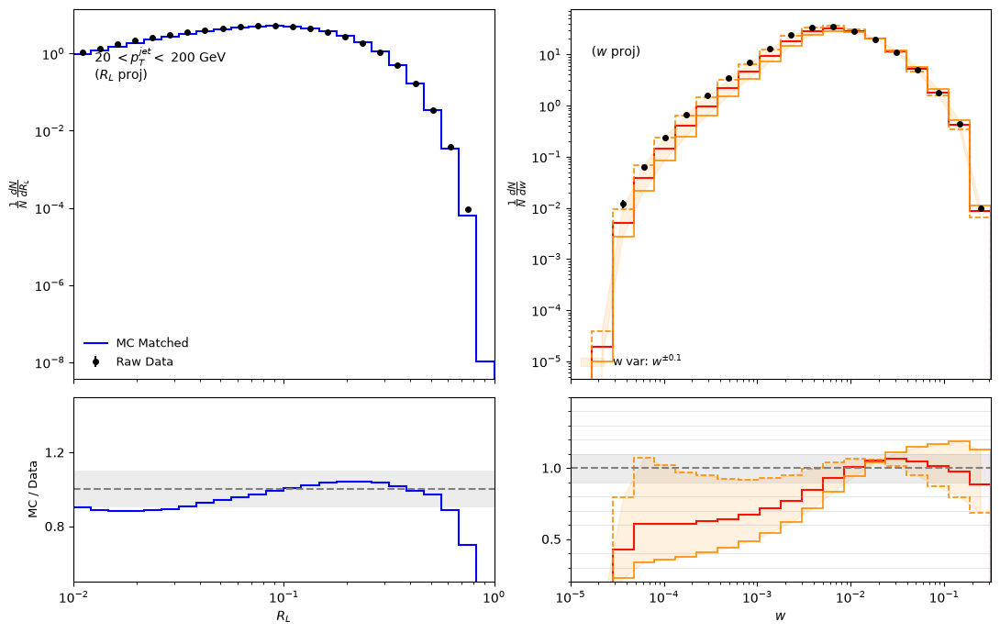

In [5]:
# Run the plotting function for AA data/MC
lab = "AA"
fig_sep = plot_separate_axes_comparison(
    lab=lab,
    h3_raw_lab=f_preunfold_data[f"{lab}_sd0.1_raw"],
    h3_reco_matched_lab=f_preunfold_rm[f"groomed_{lab}_reco_matched"]
)


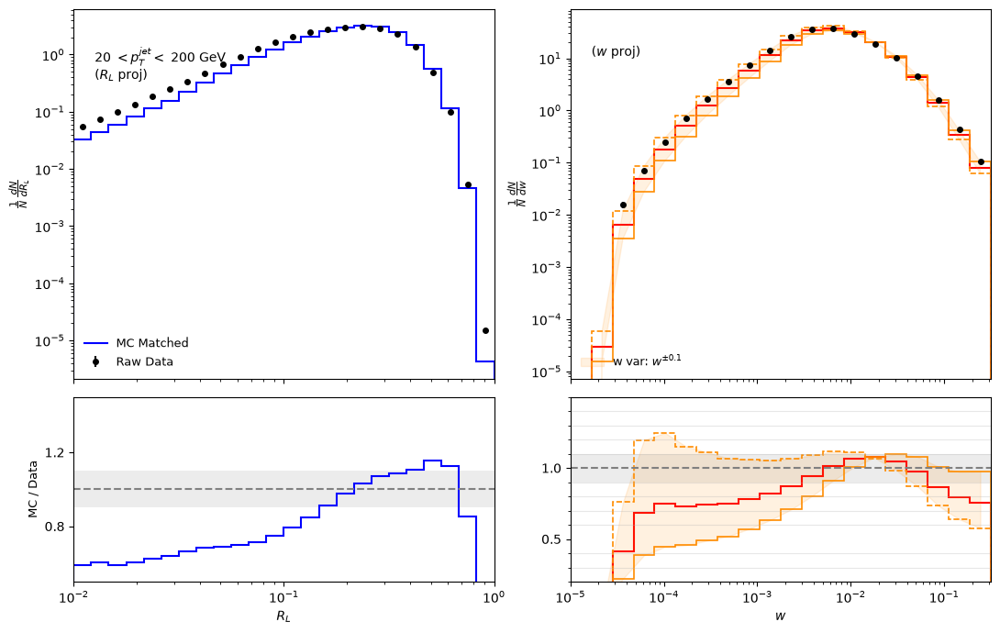

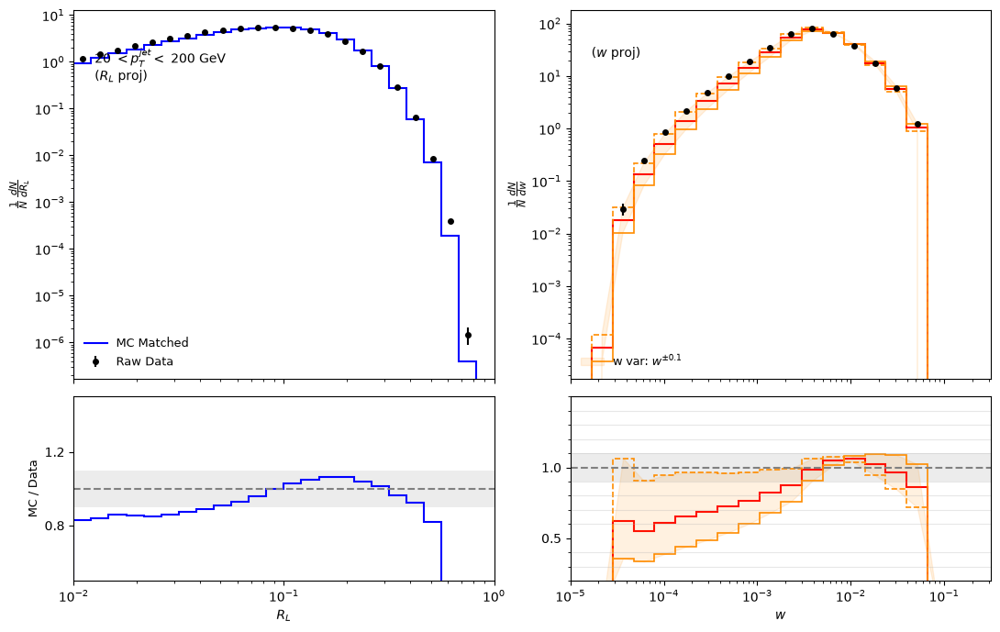

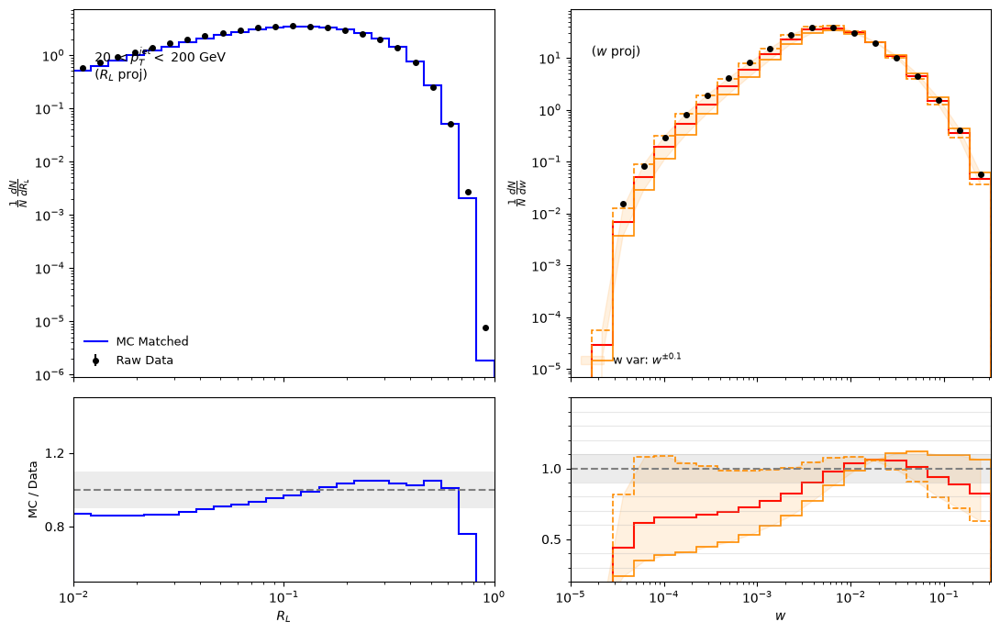

In [6]:
# Run the plotting function for AA data/MC
lab = "AB"
fig_sep = plot_separate_axes_comparison(
    lab=lab,
    h3_raw_lab=f_preunfold_data[f"{lab}_sd0.1_raw"],
    h3_reco_matched_lab=f_preunfold_rm[f"groomed_{lab}_reco_matched"]
)

# Run the plotting function for AA data/MC
lab = "BB"
fig_sep = plot_separate_axes_comparison(
    lab=lab,
    h3_raw_lab=f_preunfold_data[f"{lab}_sd0.1_raw"],
    h3_reco_matched_lab=f_preunfold_rm[f"groomed_{lab}_reco_matched"]
)

# Run the plotting function for AA data/MC
lab = "rad"
fig_sep = plot_separate_axes_comparison(
    lab=lab,
    h3_raw_lab=f_preunfold_data[f"{lab}_sd0.1_raw"],
    h3_reco_matched_lab=f_preunfold_rm[f"groomed_{lab}_reco_matched"]
)


## Shape Closure Test

Take the RM --> scale it --> project onto truth and det axes (to get scaled-det and scaled-truth) --> smear scaled-det with data statistical errors --> unfold with original RM --> the resulting *unfolded* distribution gets compared to scaled-truth MC 

Need:
- unfolded MC distribution (truth level)
- scaled truth-level MC

In [7]:
# Variations available in unfolding_tests.C / unfolded_tests_AA.root
VARIATIONS = ["pt015_w01", "ptm015_wm01"]
VAR_TEX = {"pt015_w01": r"$p_T^{+0.15}\,w^{+0.1}$", "ptm015_wm01": r"$p_T^{-0.15}\,w^{-0.1}$"}

# 3D unfolded hists per variation: h3_shape_unf[lab][var] = [iter1, ..., iter5]
h3_shape_unf = {lab: {var: [f_closure_tests[f"shape_closure/Shape_{lab}_{var}_Unfolded_iter{i}"]
                            for i in range(1, n_iter+1)]
                     for var in VARIATIONS} for lab in labels}

# Scaled truth reference per variation (written by the macro)
h3_shape_truth = {lab: {var: f_closure_tests[f"shape_closure/Shape_{lab}_{var}_truth"]
                        for var in VARIATIONS} for lab in labels}

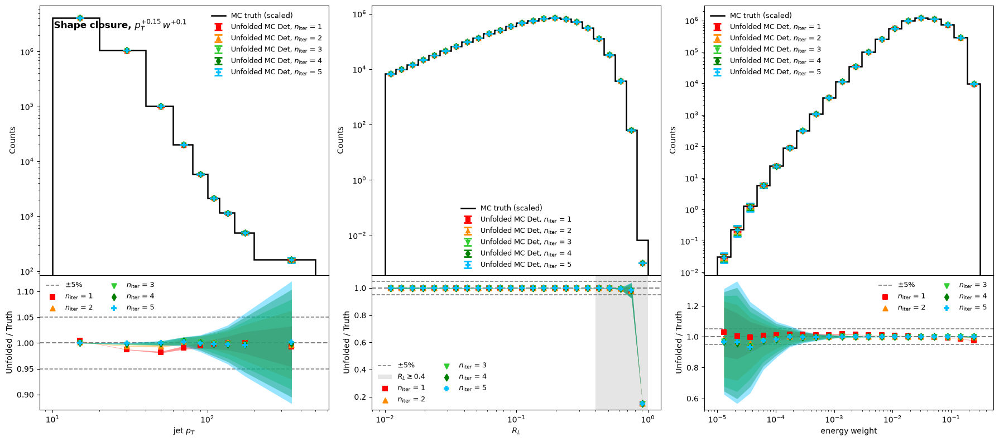

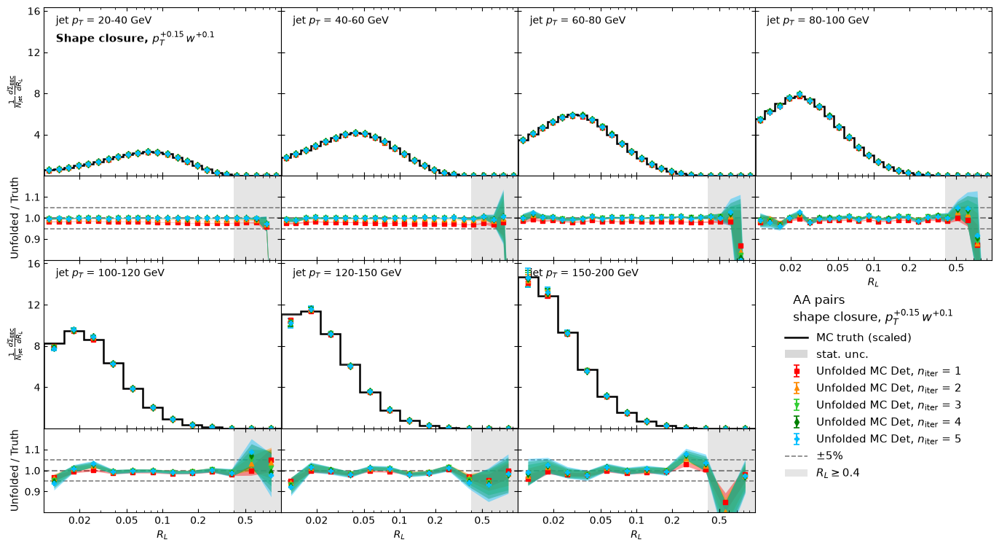

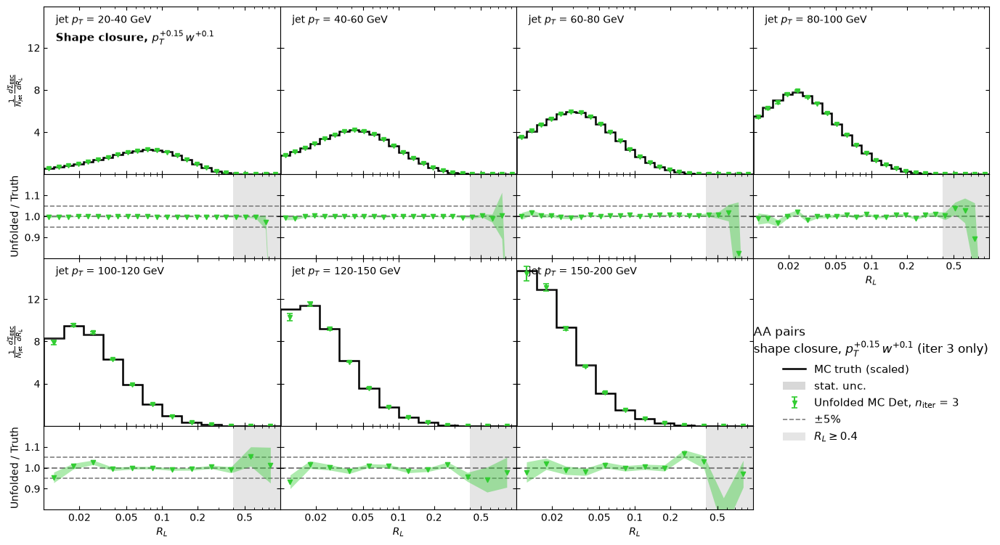

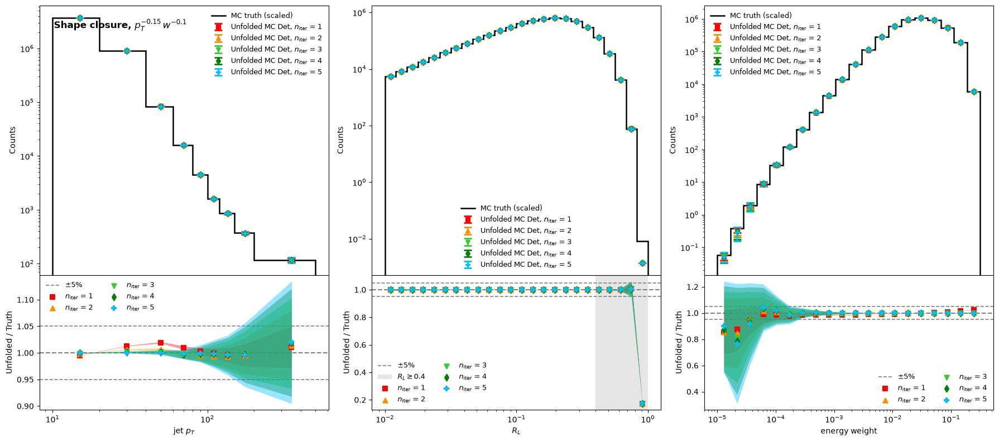

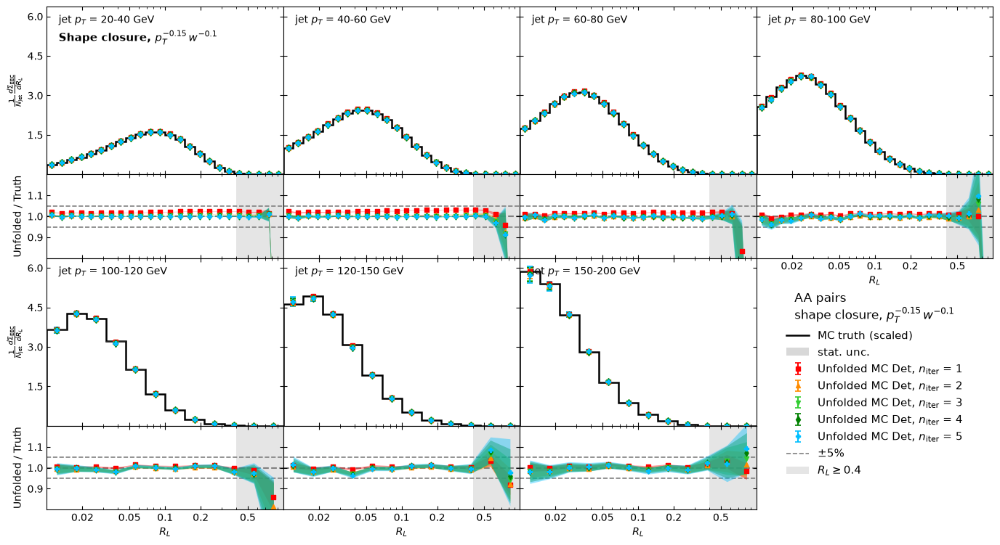

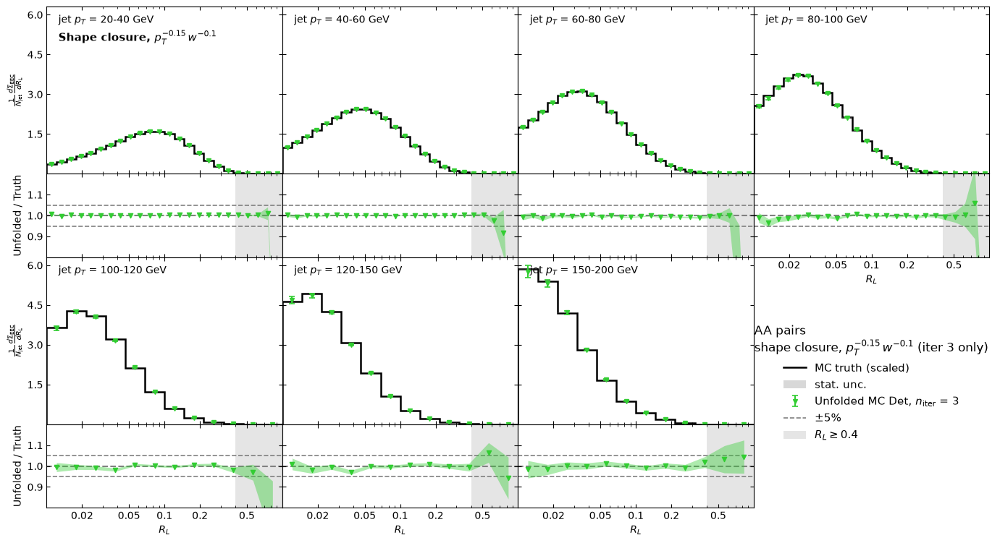

In [8]:
# Shape closure - all variations
lab = "AA"

for var in VARIATIONS:
    plot_closure_section(lab, "shape", h3_shape_truth[lab][var], h3_shape_unf[lab][var],
                         "MC truth (scaled)", inp, var=var, extralabel=f"shape closure, {VAR_TEX[var]}")

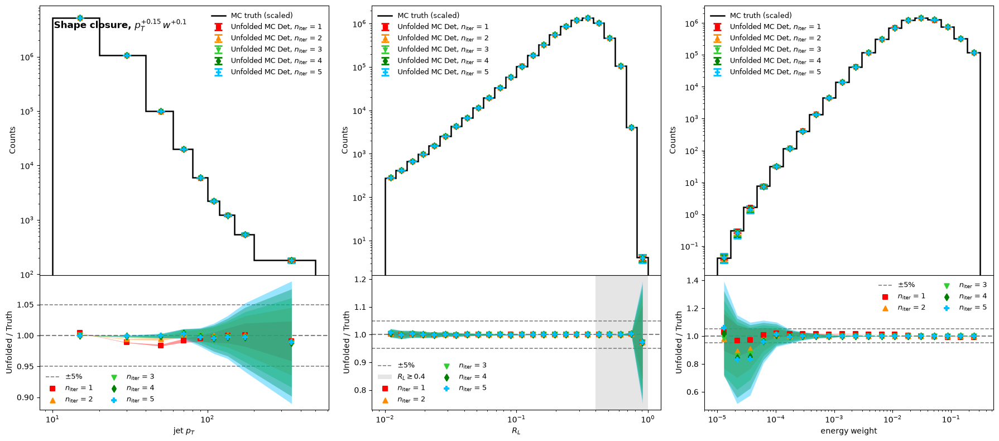

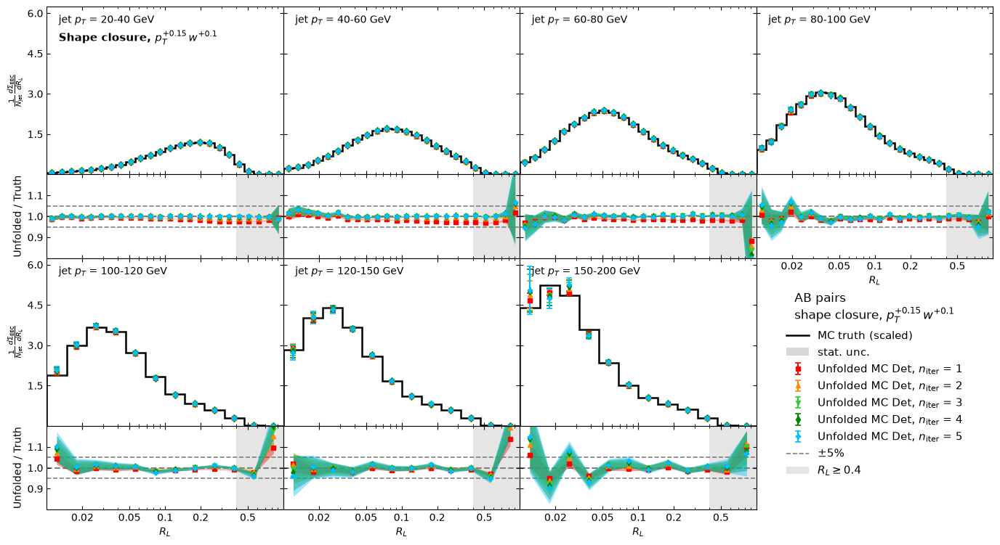

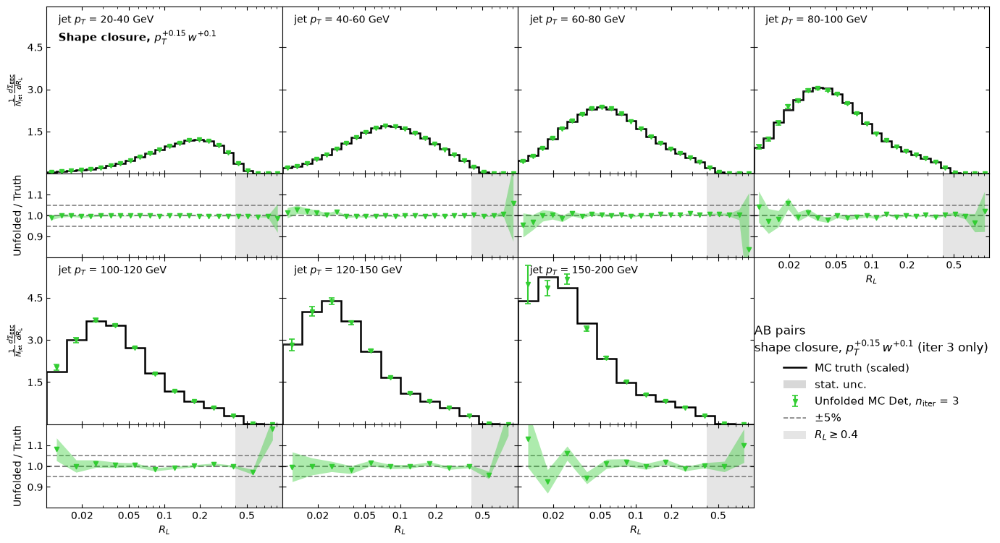

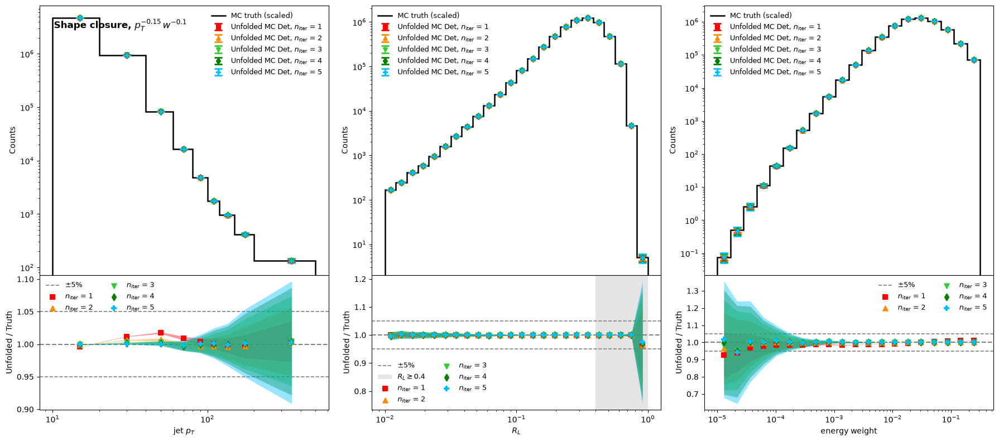

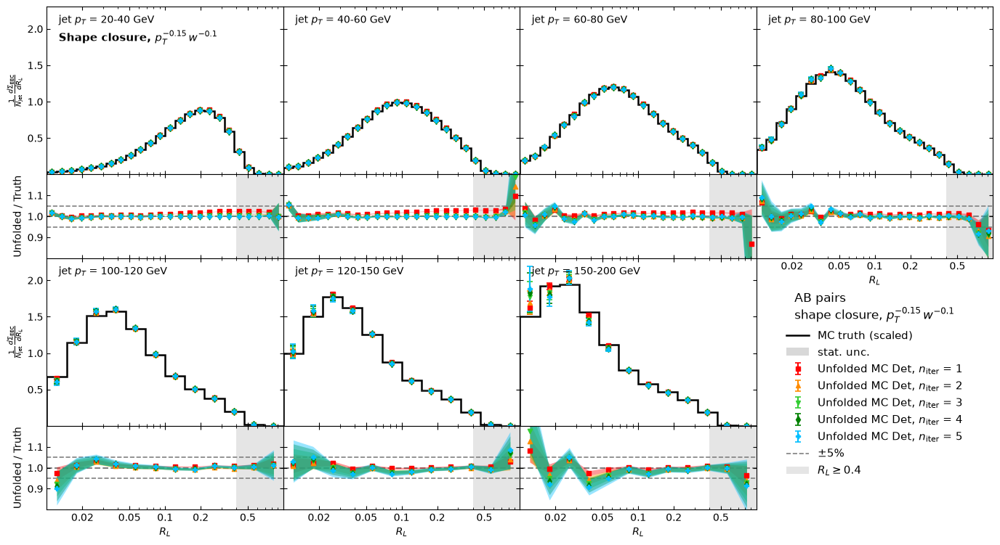

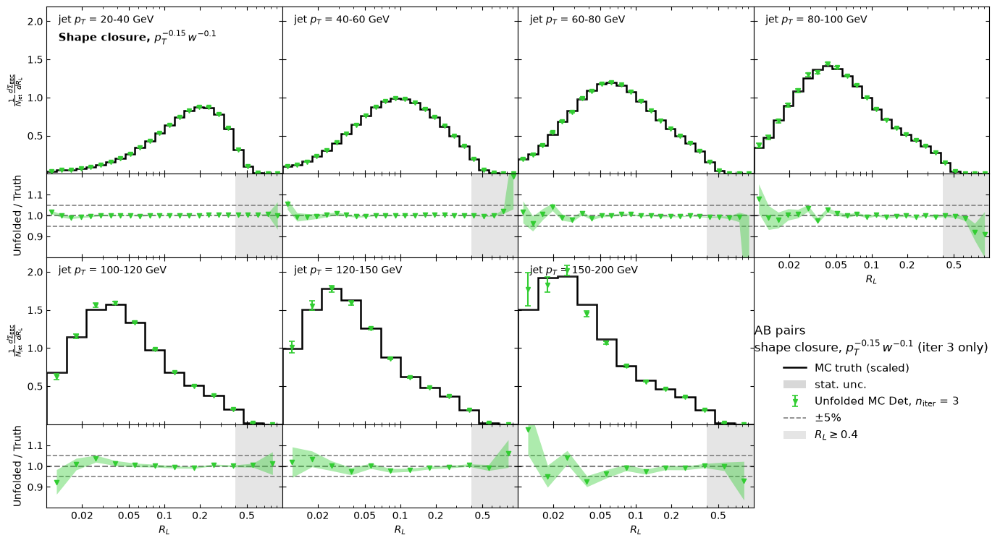

In [9]:
# Shape closure - all variations
lab = "AB"

for var in VARIATIONS:
    plot_closure_section(lab, "shape", h3_shape_truth[lab][var], h3_shape_unf[lab][var],
                         "MC truth (scaled)", inp, var=var, extralabel=f"shape closure, {VAR_TEX[var]}")

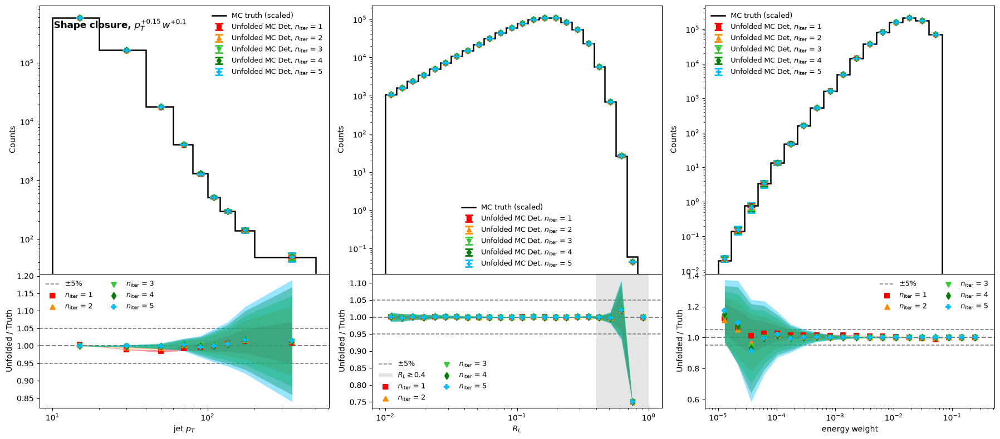

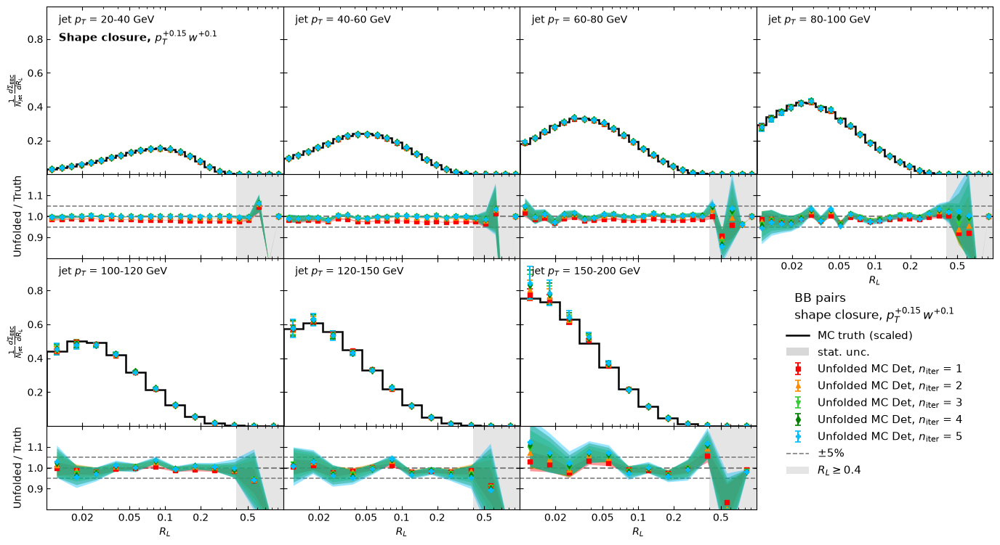

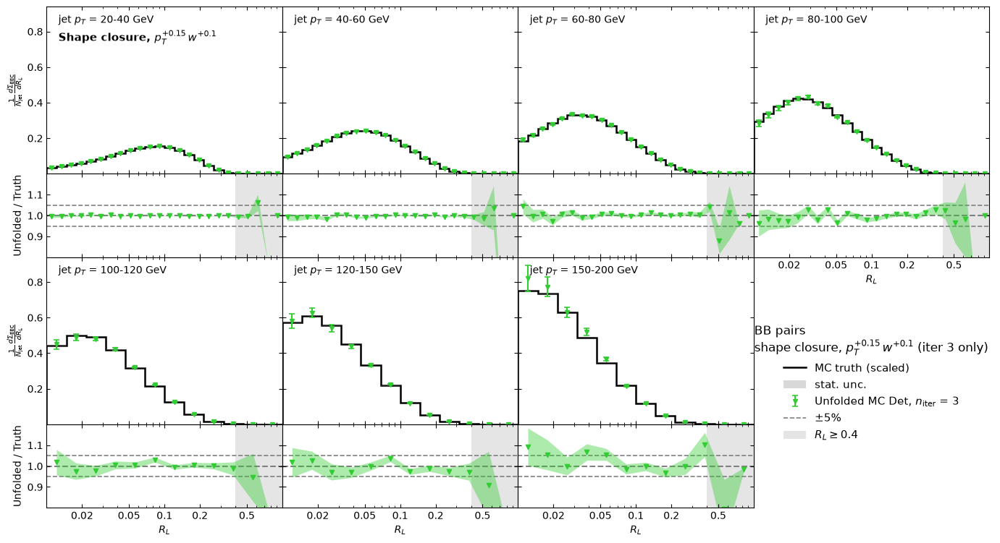

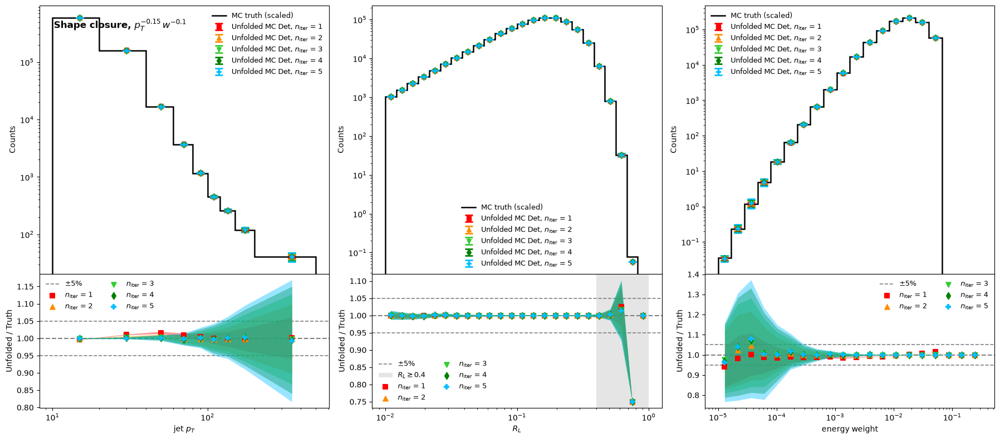

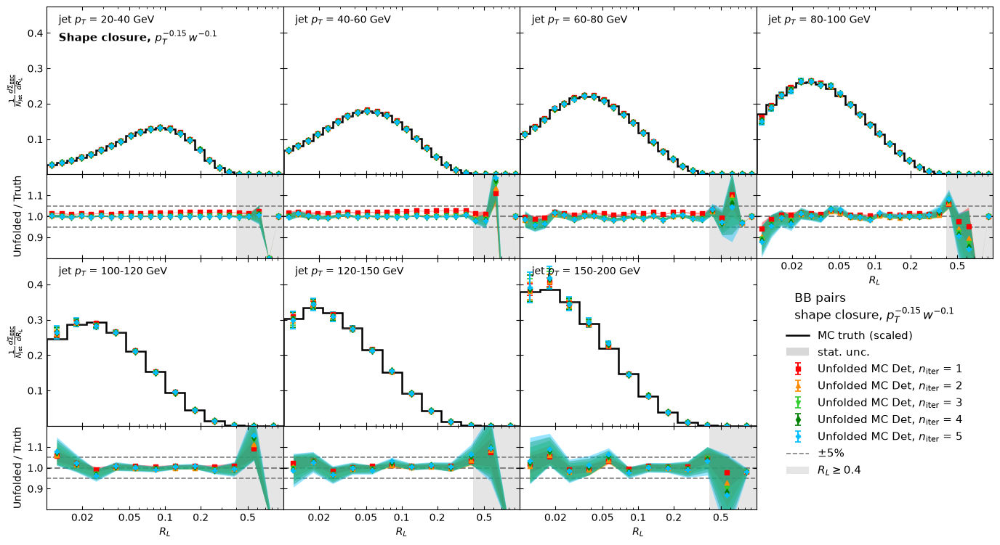

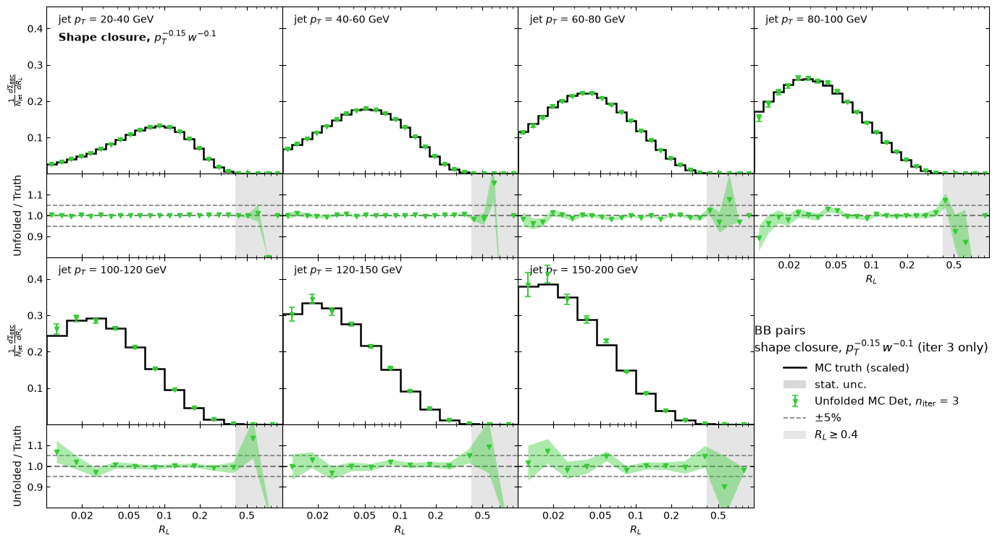

In [10]:
# Shape closure - all variations
lab = "BB"

for var in VARIATIONS:
    plot_closure_section(lab, "shape", h3_shape_truth[lab][var], h3_shape_unf[lab][var],
                         "MC truth (scaled)", inp, var=var, extralabel=f"shape closure, {VAR_TEX[var]}")

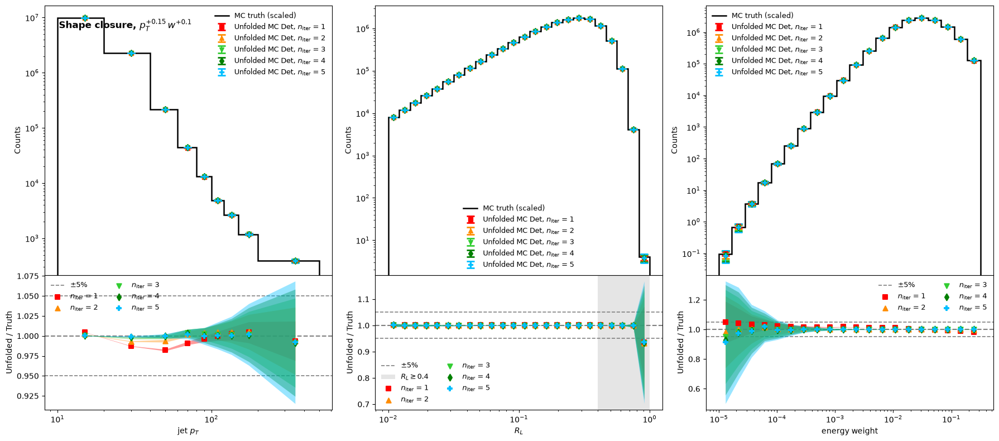

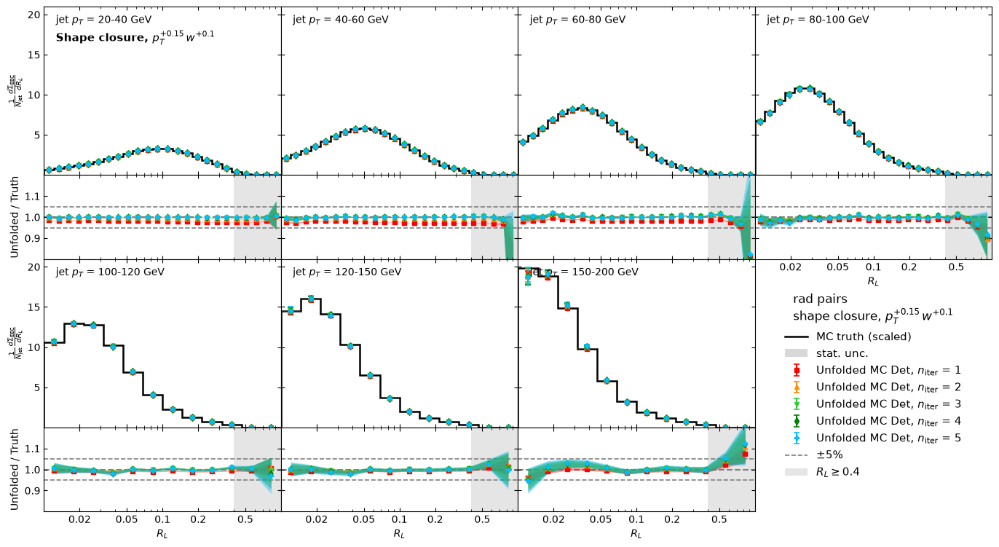

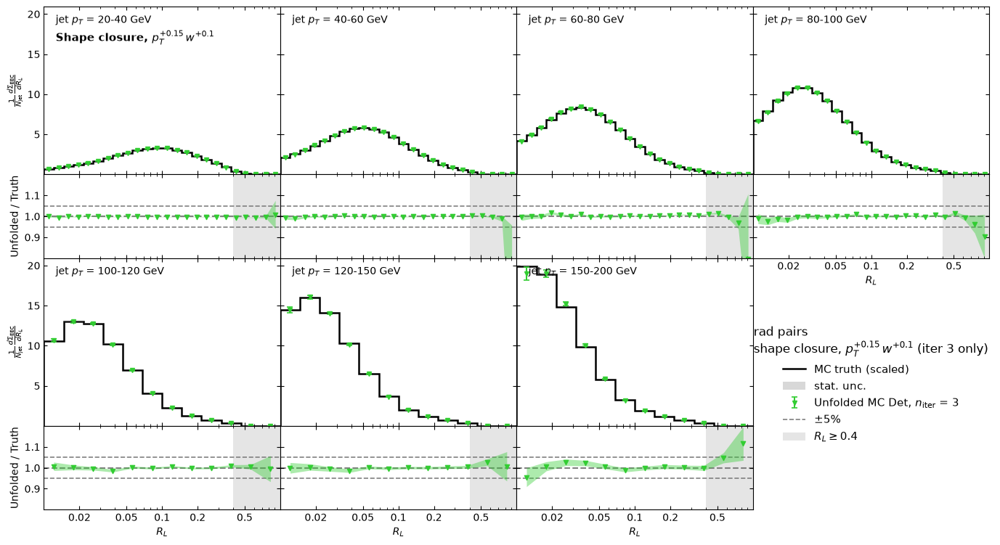

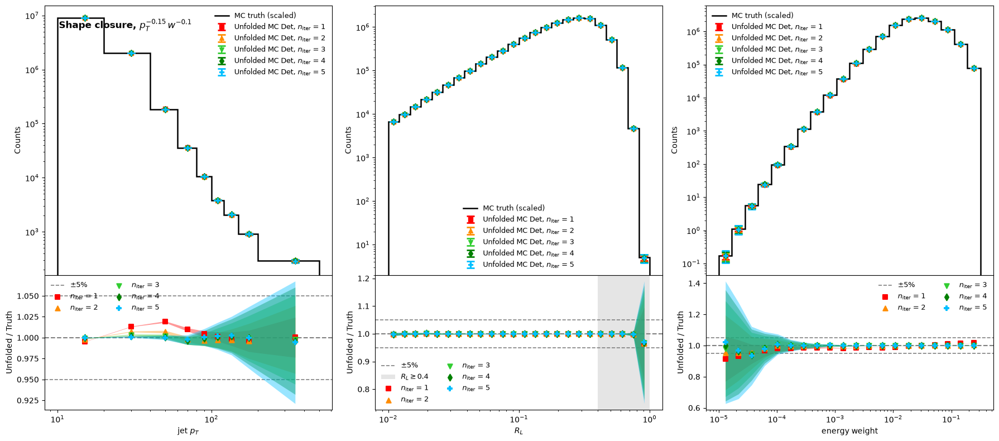

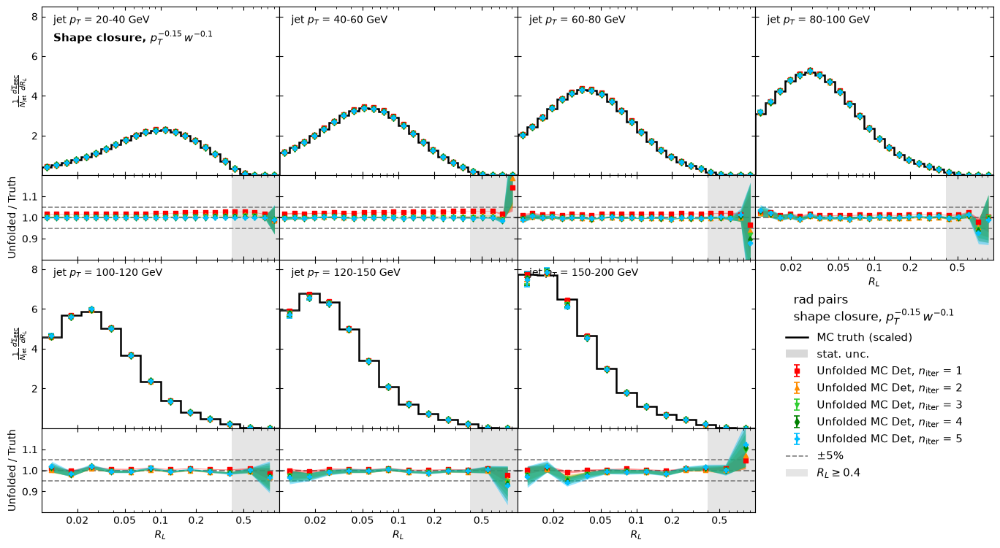

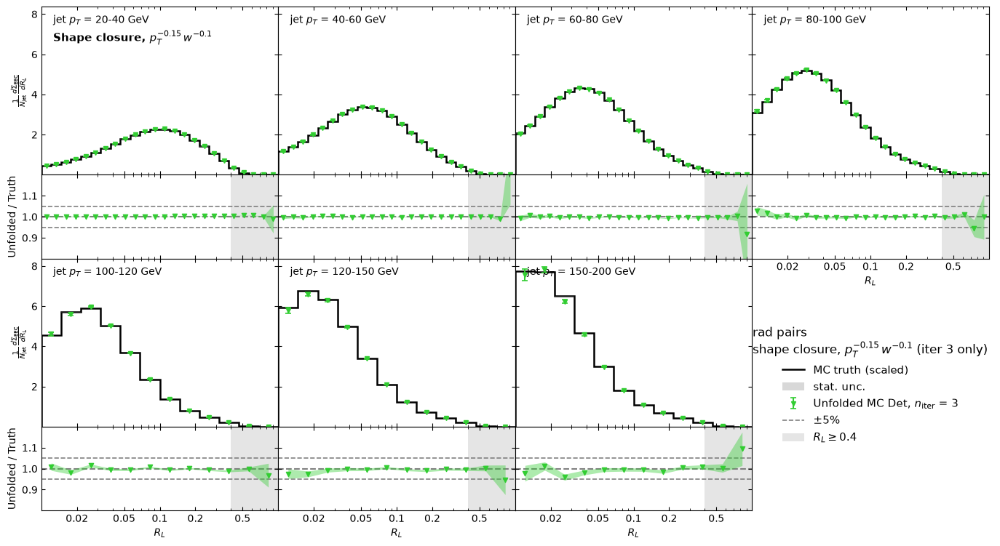

In [11]:
# Shape closure - all variations
lab = "rad"

for var in VARIATIONS:
    plot_closure_section(lab, "shape", h3_shape_truth[lab][var], h3_shape_unf[lab][var],
                         "MC truth (scaled)", inp, var=var, extralabel=f"shape closure, {VAR_TEX[var]}")

## Prior Closure Test

Take the (matched) det level MC --> smear it with data statistical errors --> also take the RM --> scale it --> unfold smeared det-level MC with scaled RM --> the resulting *unfolded* distribution gets compared to original (matched) truth MC 

Need:
- unfolded MC distribution (truth level)
- original truth-level MC

In [12]:
# 3D unfolded hists per variation: h3_prior_unf[lab][var] = [iter1, ..., iter5]
h3_prior_unf = {lab: {var: [f_closure_tests[f"prior_closure/Prior_{lab}_{var}_Unfolded_iter{i}"]
                            for i in range(1, n_iter+1)]
                     for var in VARIATIONS} for lab in labels}

# Reference: response truth (Htruth) for every prior variation -- the level the unfolding returns

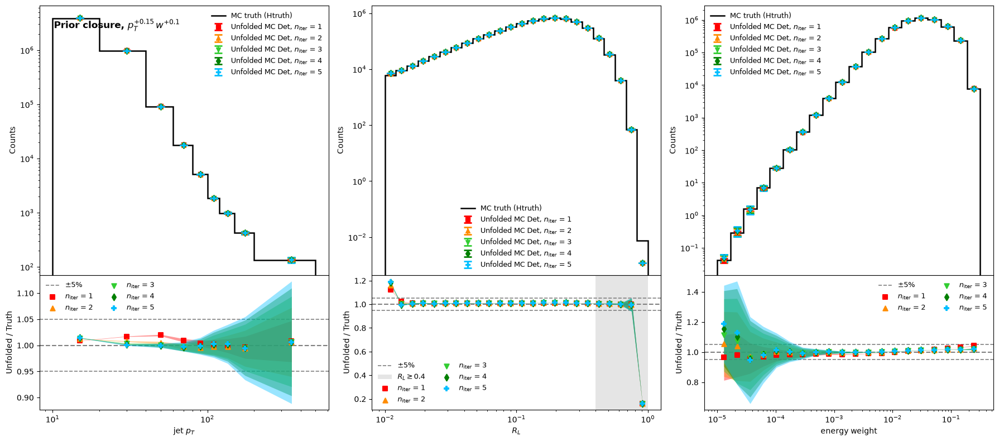

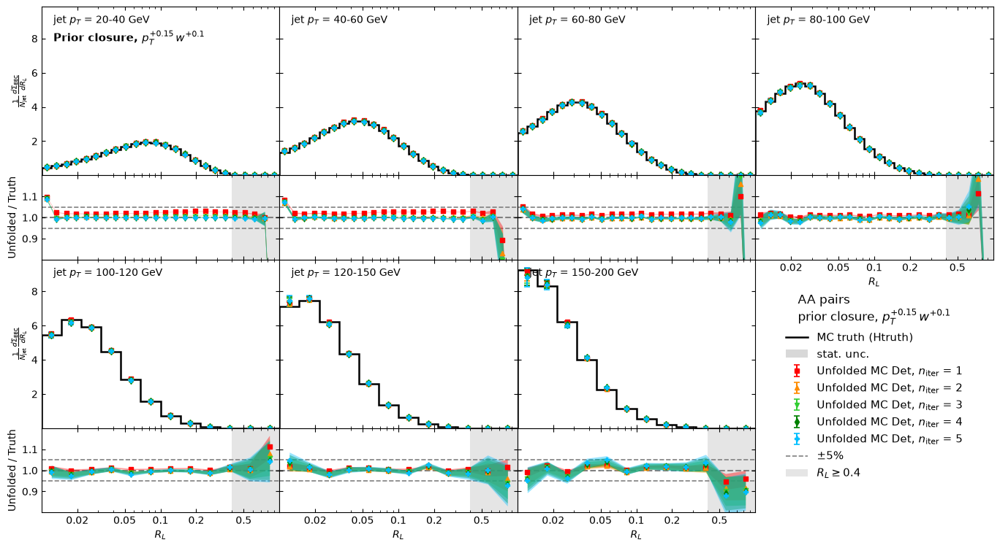

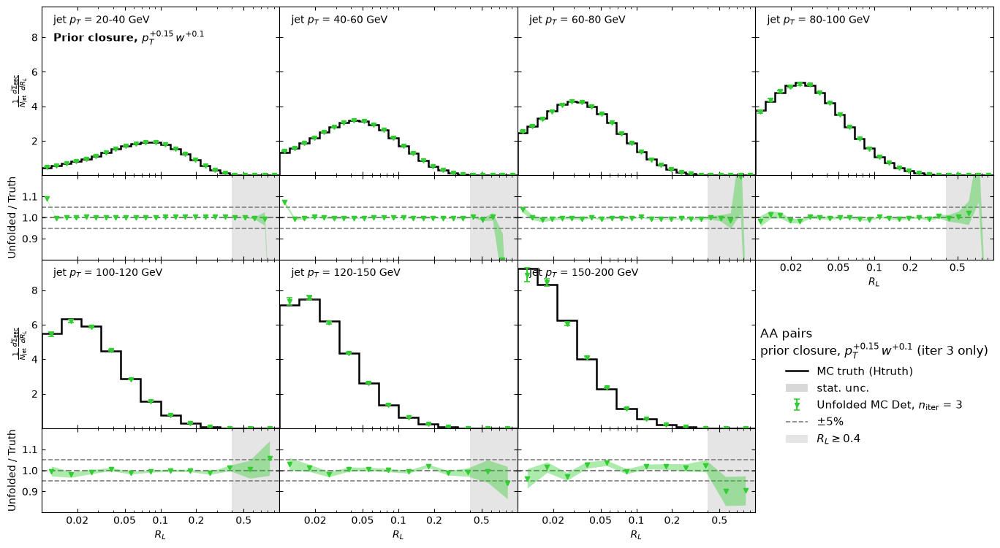

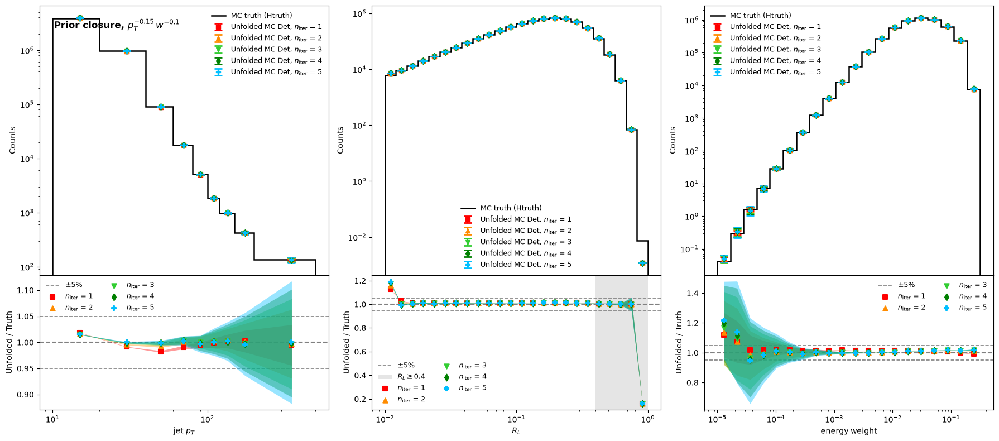

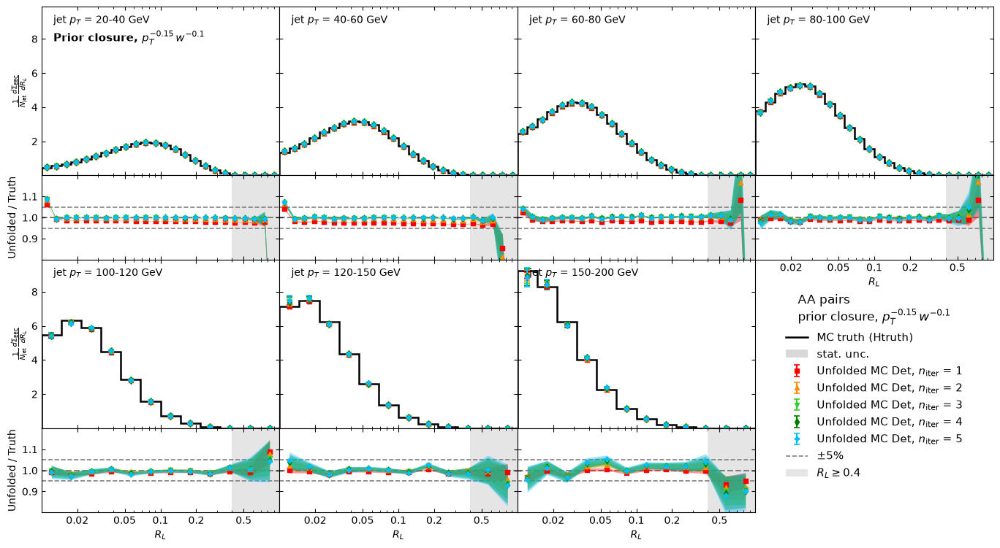

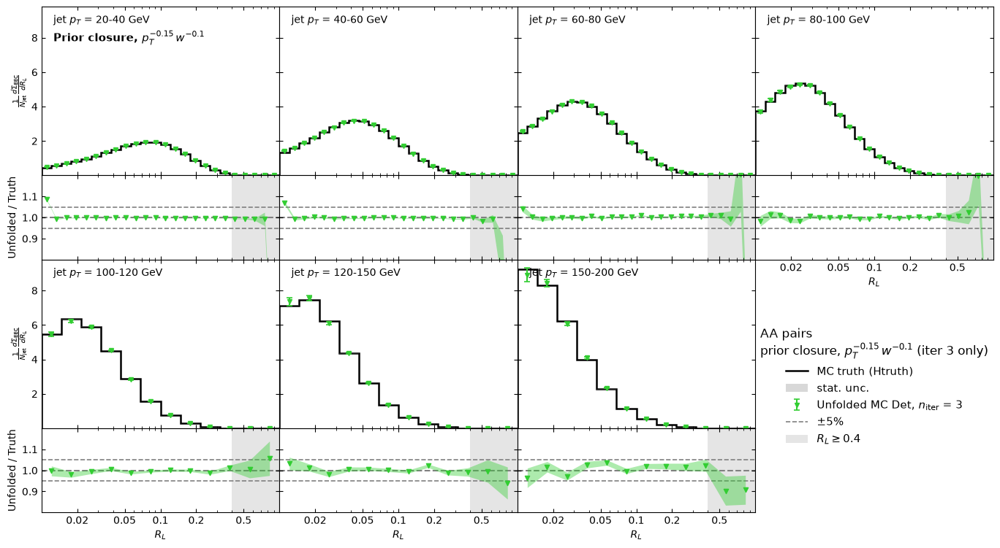

In [13]:
# Prior closure - all variations (reference = Htruth for all of them)
lab = "AA"

for var in VARIATIONS:
    plot_closure_section(lab, "prior", h3_truth[lab], h3_prior_unf[lab][var],
                         "MC truth (Htruth)", inp, var=var, extralabel=f"prior closure, {VAR_TEX[var]}")

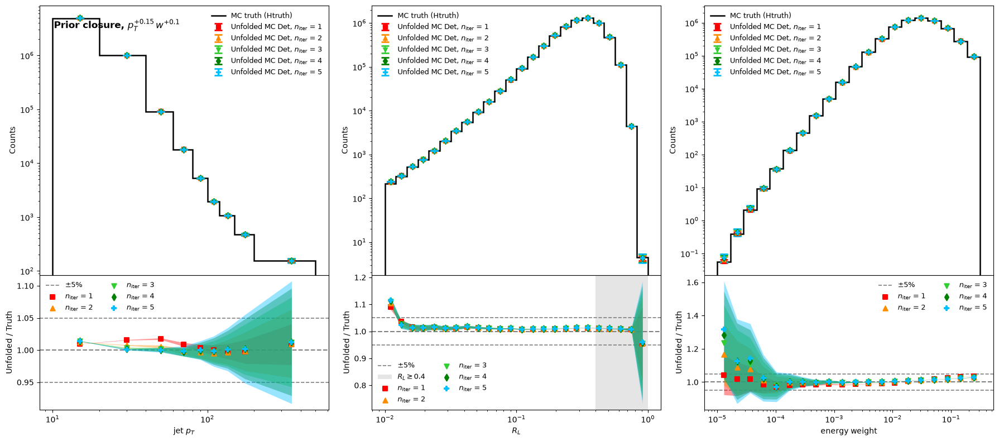

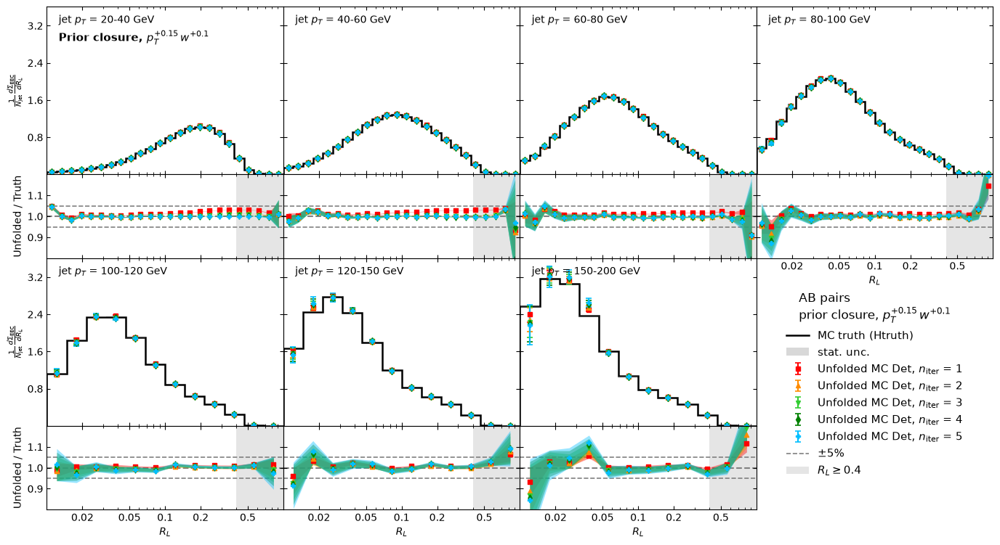

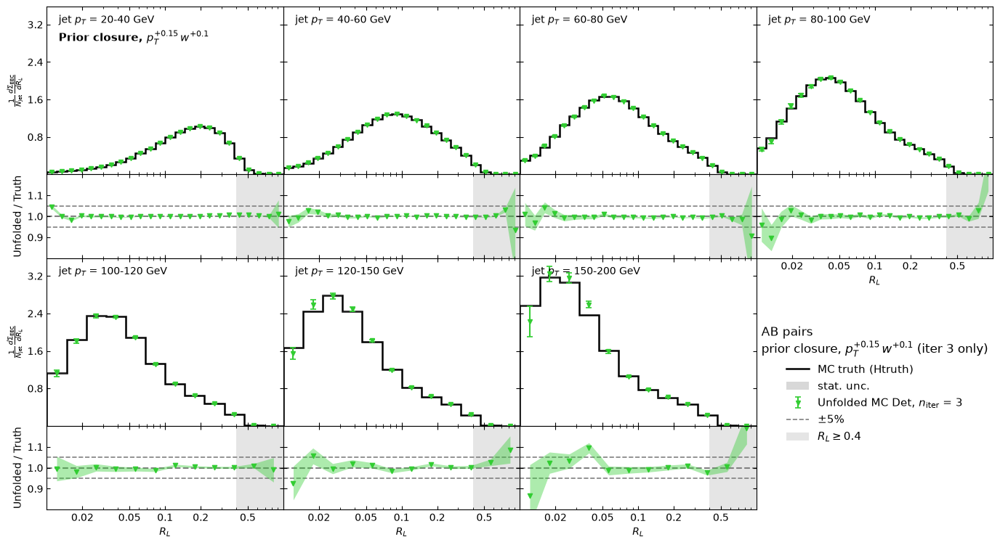

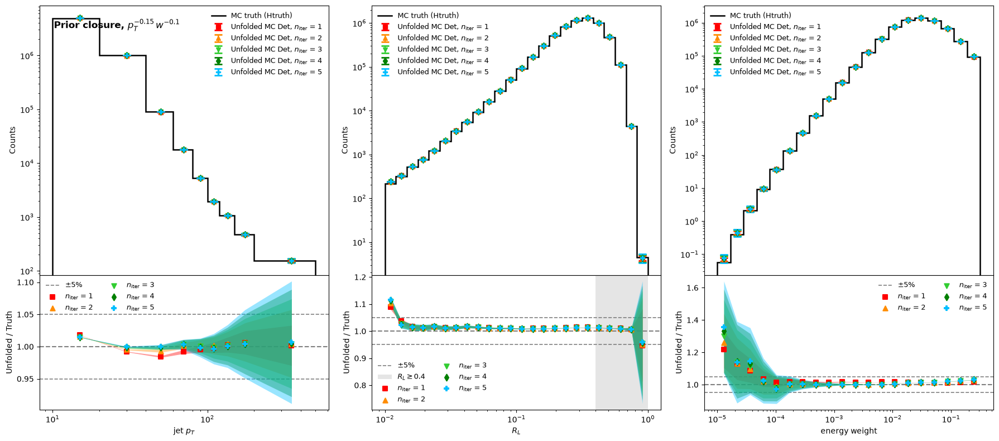

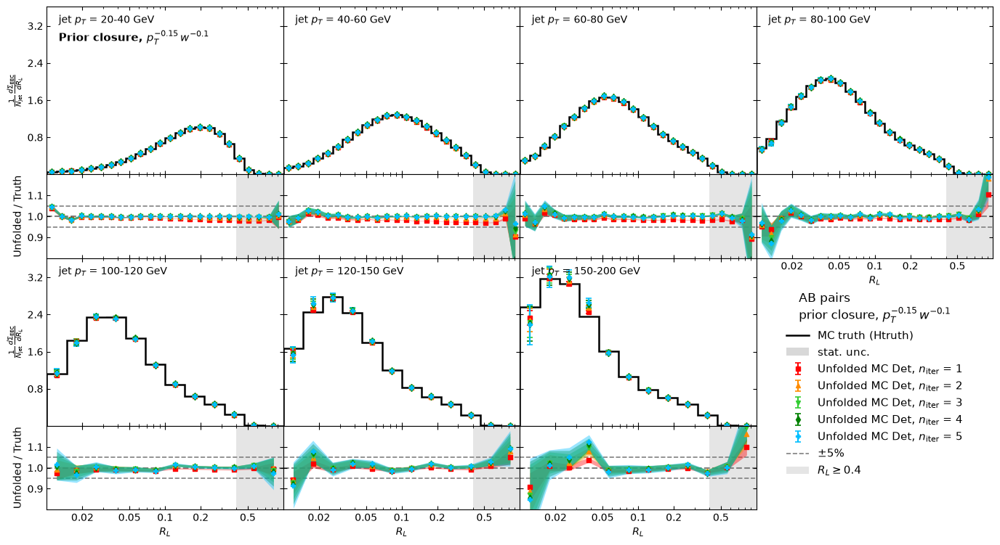

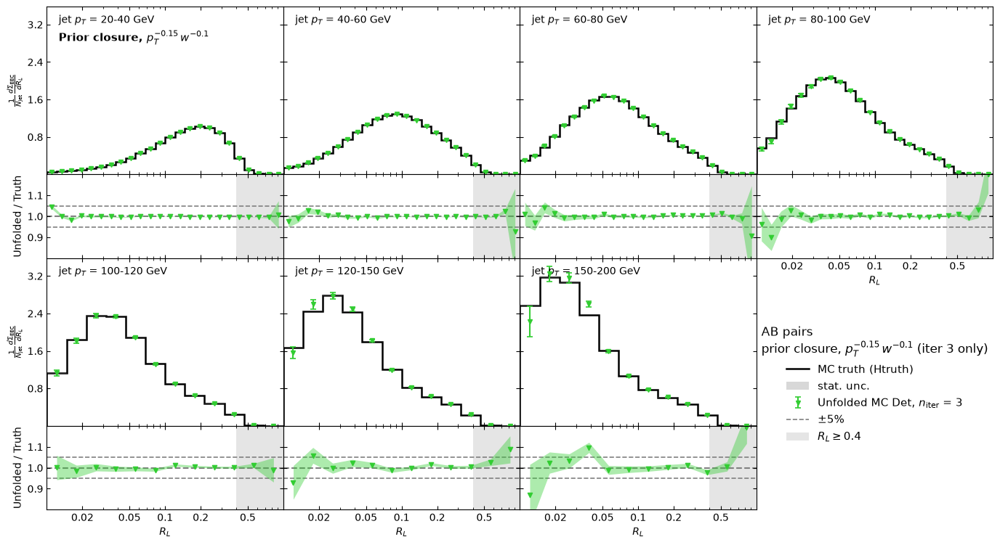

In [14]:
# Prior closure - all variations (reference = Htruth for all of them)
lab = "AB"

for var in VARIATIONS:
    plot_closure_section(lab, "prior", h3_truth[lab], h3_prior_unf[lab][var],
                         "MC truth (Htruth)", inp, var=var, extralabel=f"prior closure, {VAR_TEX[var]}")

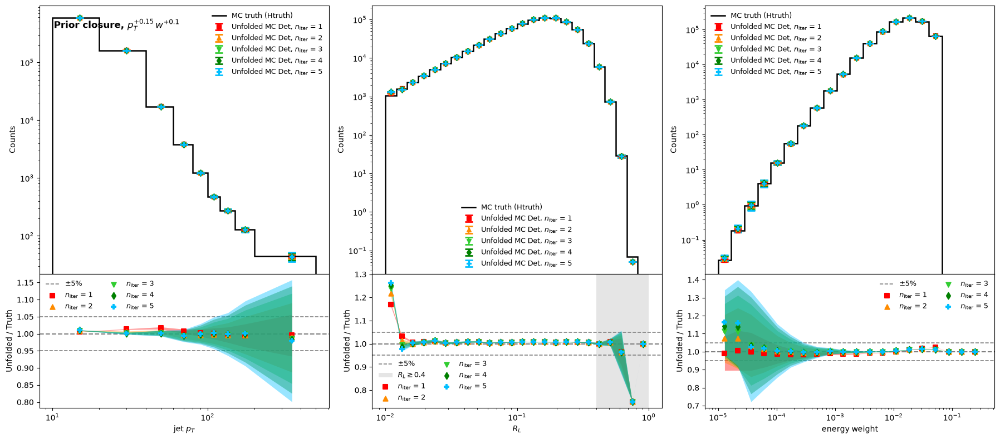

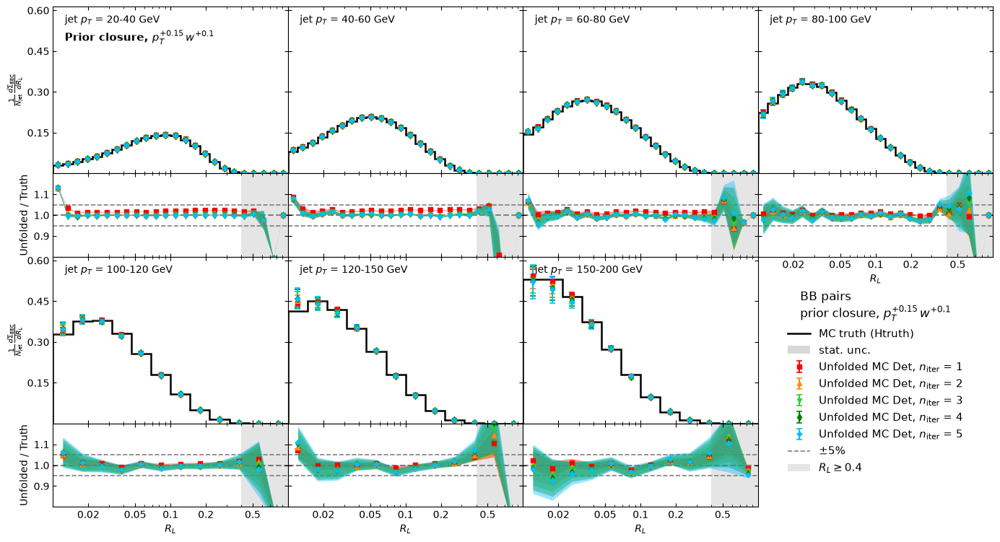

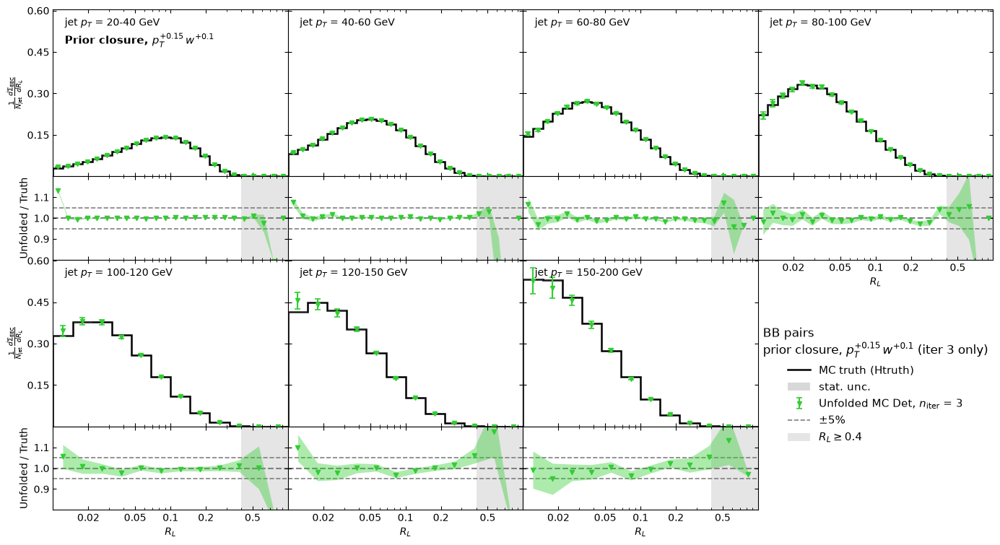

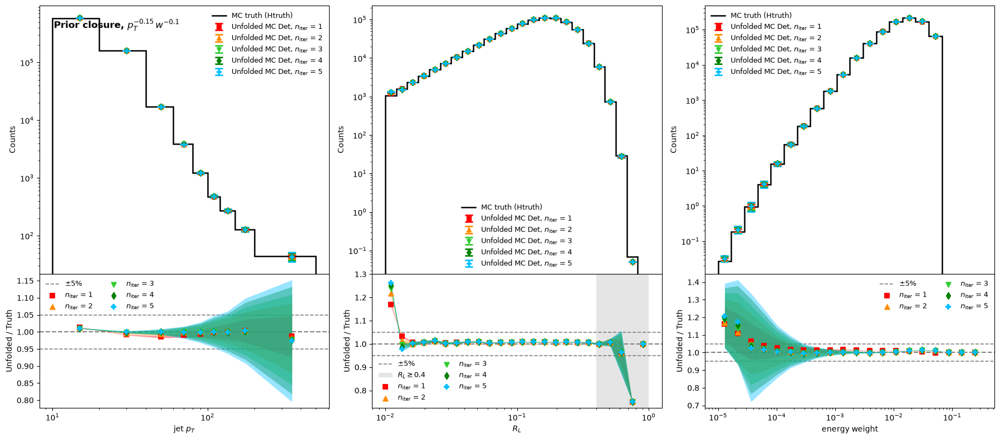

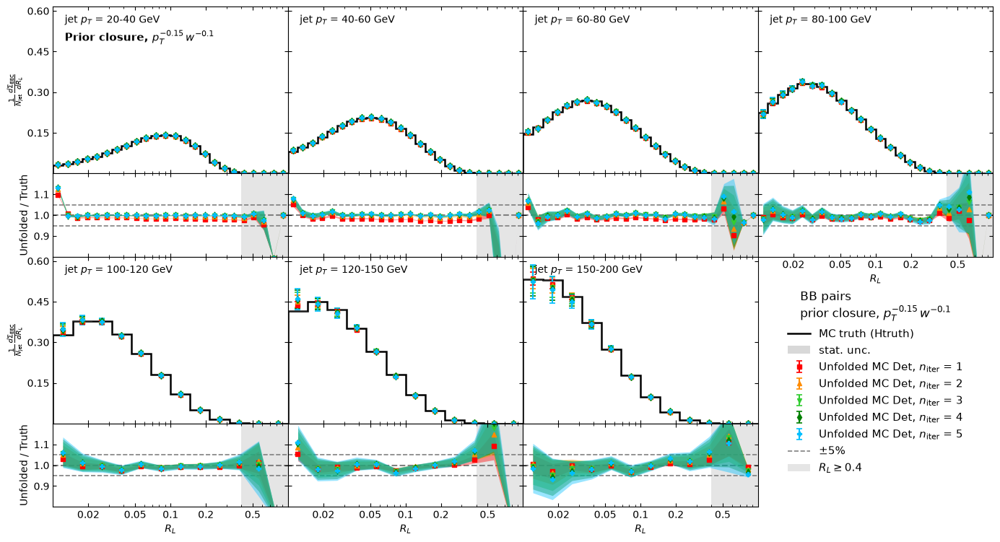

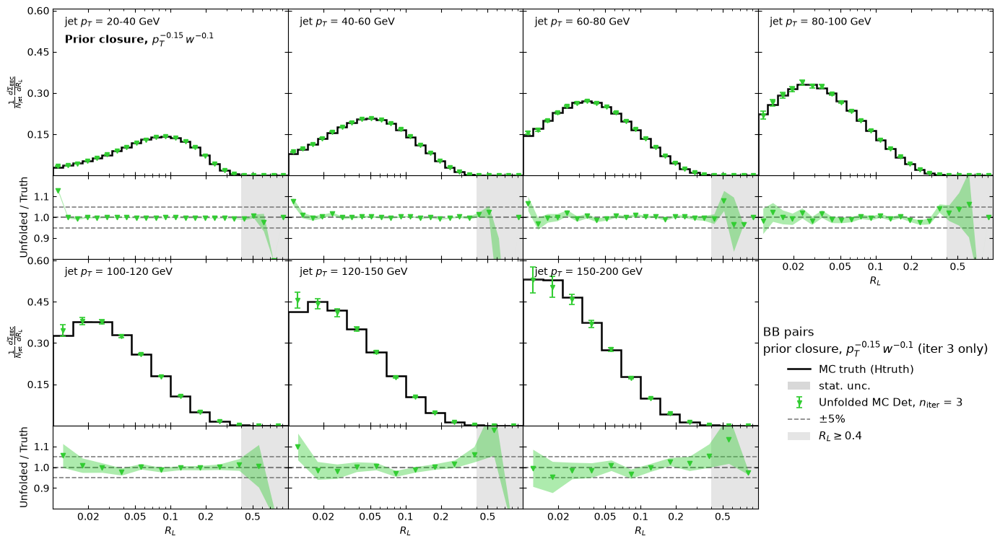

In [15]:
# Prior closure - all variations (reference = Htruth for all of them)
lab = "BB"

for var in VARIATIONS:
    plot_closure_section(lab, "prior", h3_truth[lab], h3_prior_unf[lab][var],
                         "MC truth (Htruth)", inp, var=var, extralabel=f"prior closure, {VAR_TEX[var]}")

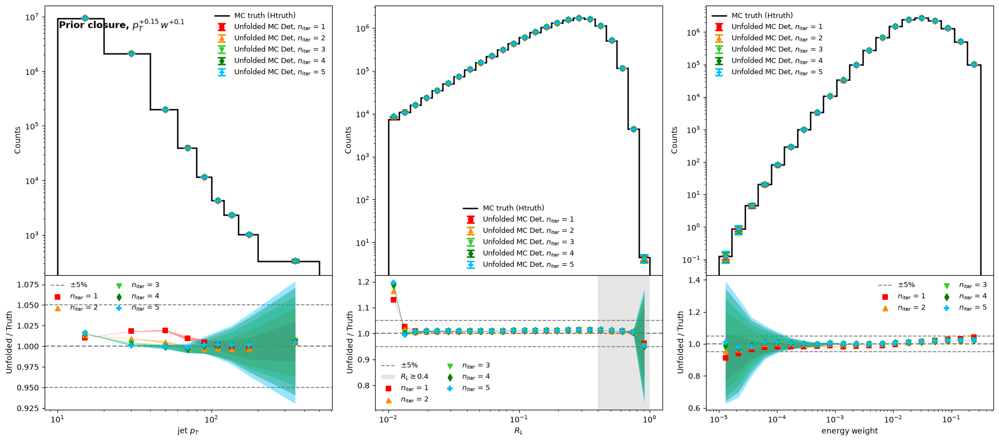

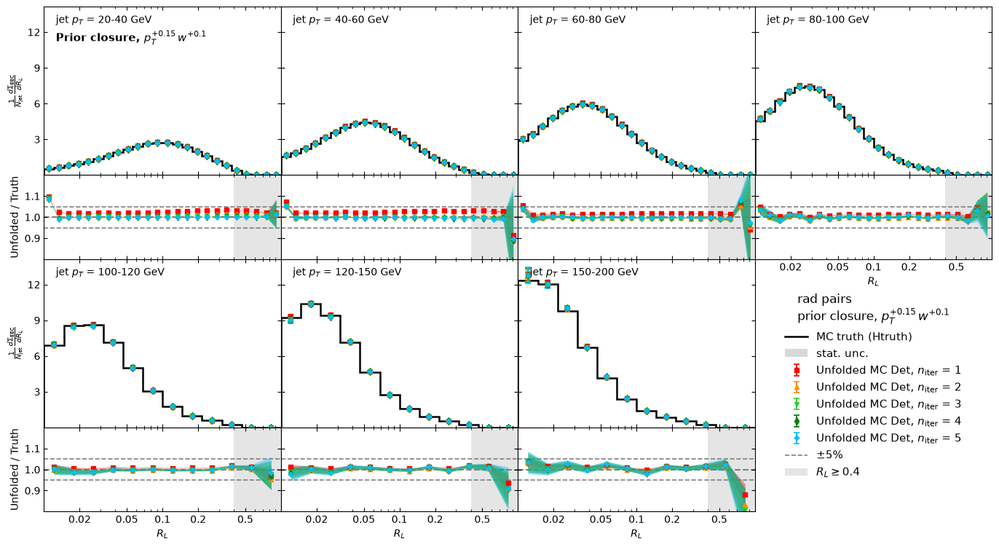

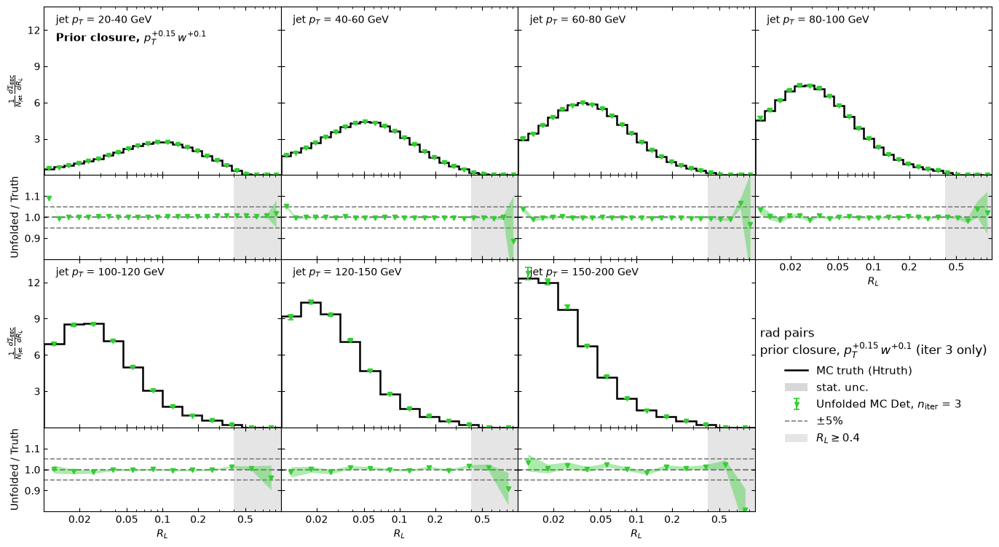

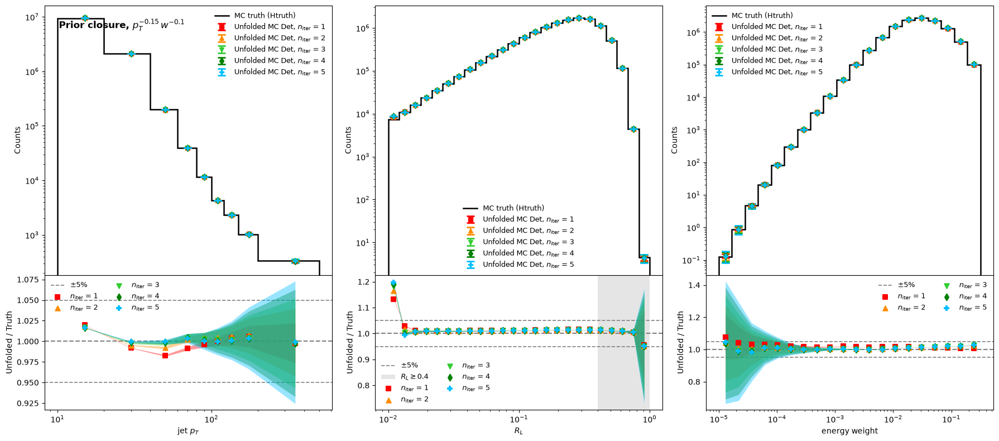

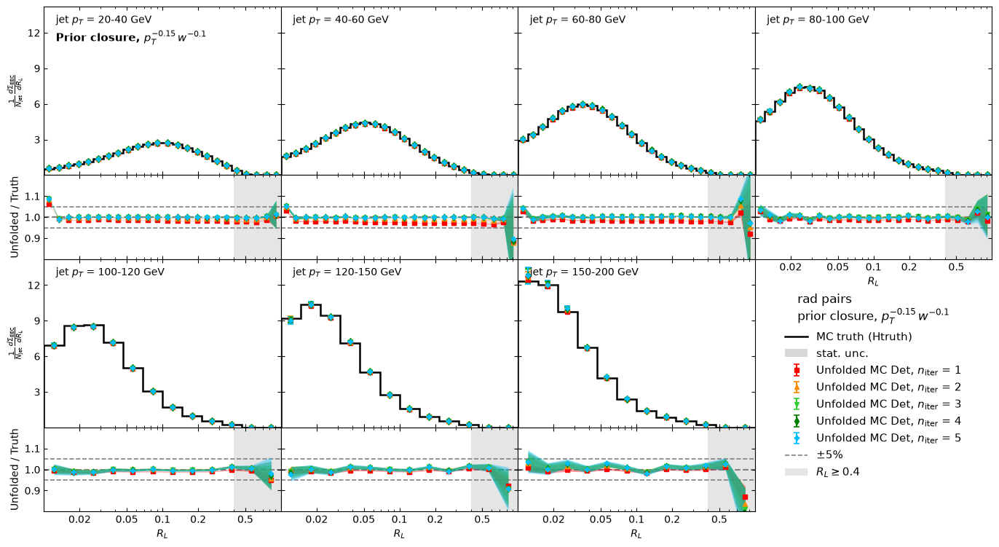

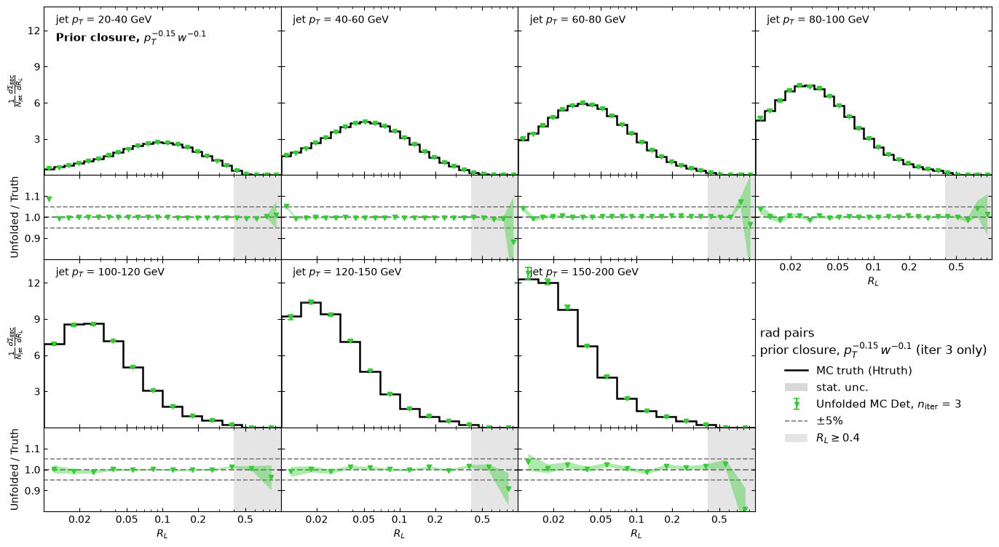

In [16]:
# Prior closure - all variations (reference = Htruth for all of them)
lab = "rad"

for var in VARIATIONS:
    plot_closure_section(lab, "prior", h3_truth[lab], h3_prior_unf[lab][var],
                         "MC truth (Htruth)", inp, var=var, extralabel=f"prior closure, {VAR_TEX[var]}")